In [2]:
!pip install numpy pandas matplotlib



                     365-DAY BUOY PERFORMANCE METRICS                      
Simulation duration       : 365 days
Total solar energy        : 89,992.5 Wh
Total wave energy         : 6,536.0 Wh
Total harvested energy    : 96,528.5 Wh
Total load energy         : 83,597.3 Wh
Net energy balance        : 12,931.1 Wh
Average daily harvest     : 264.5 Wh/day
Average daily load        : 229.0 Wh/day
Minimum usable SOC        : 17.1 %
Final usable SOC          : 32.5 %
Normal mode               : 3690.5 h
Power-saver mode          : 4192.0 h
Survival mode             : 877.5 h
Shutdown mode             : 0.0 h
Critical mode             : 877.5 h
Critical events           : 91
Longest critical event   : 49.0 h
Solar contribution        : 93.2 %
Wave contribution         : 6.8 %


                                         MONTHLY ENERGY & SURVIVAL SUMMARY                                         
Month  Avg SST   Min SST   Avg Hs    Solar Wh     Wave Wh     Load Wh     Net Wh      Min SOC   Critic

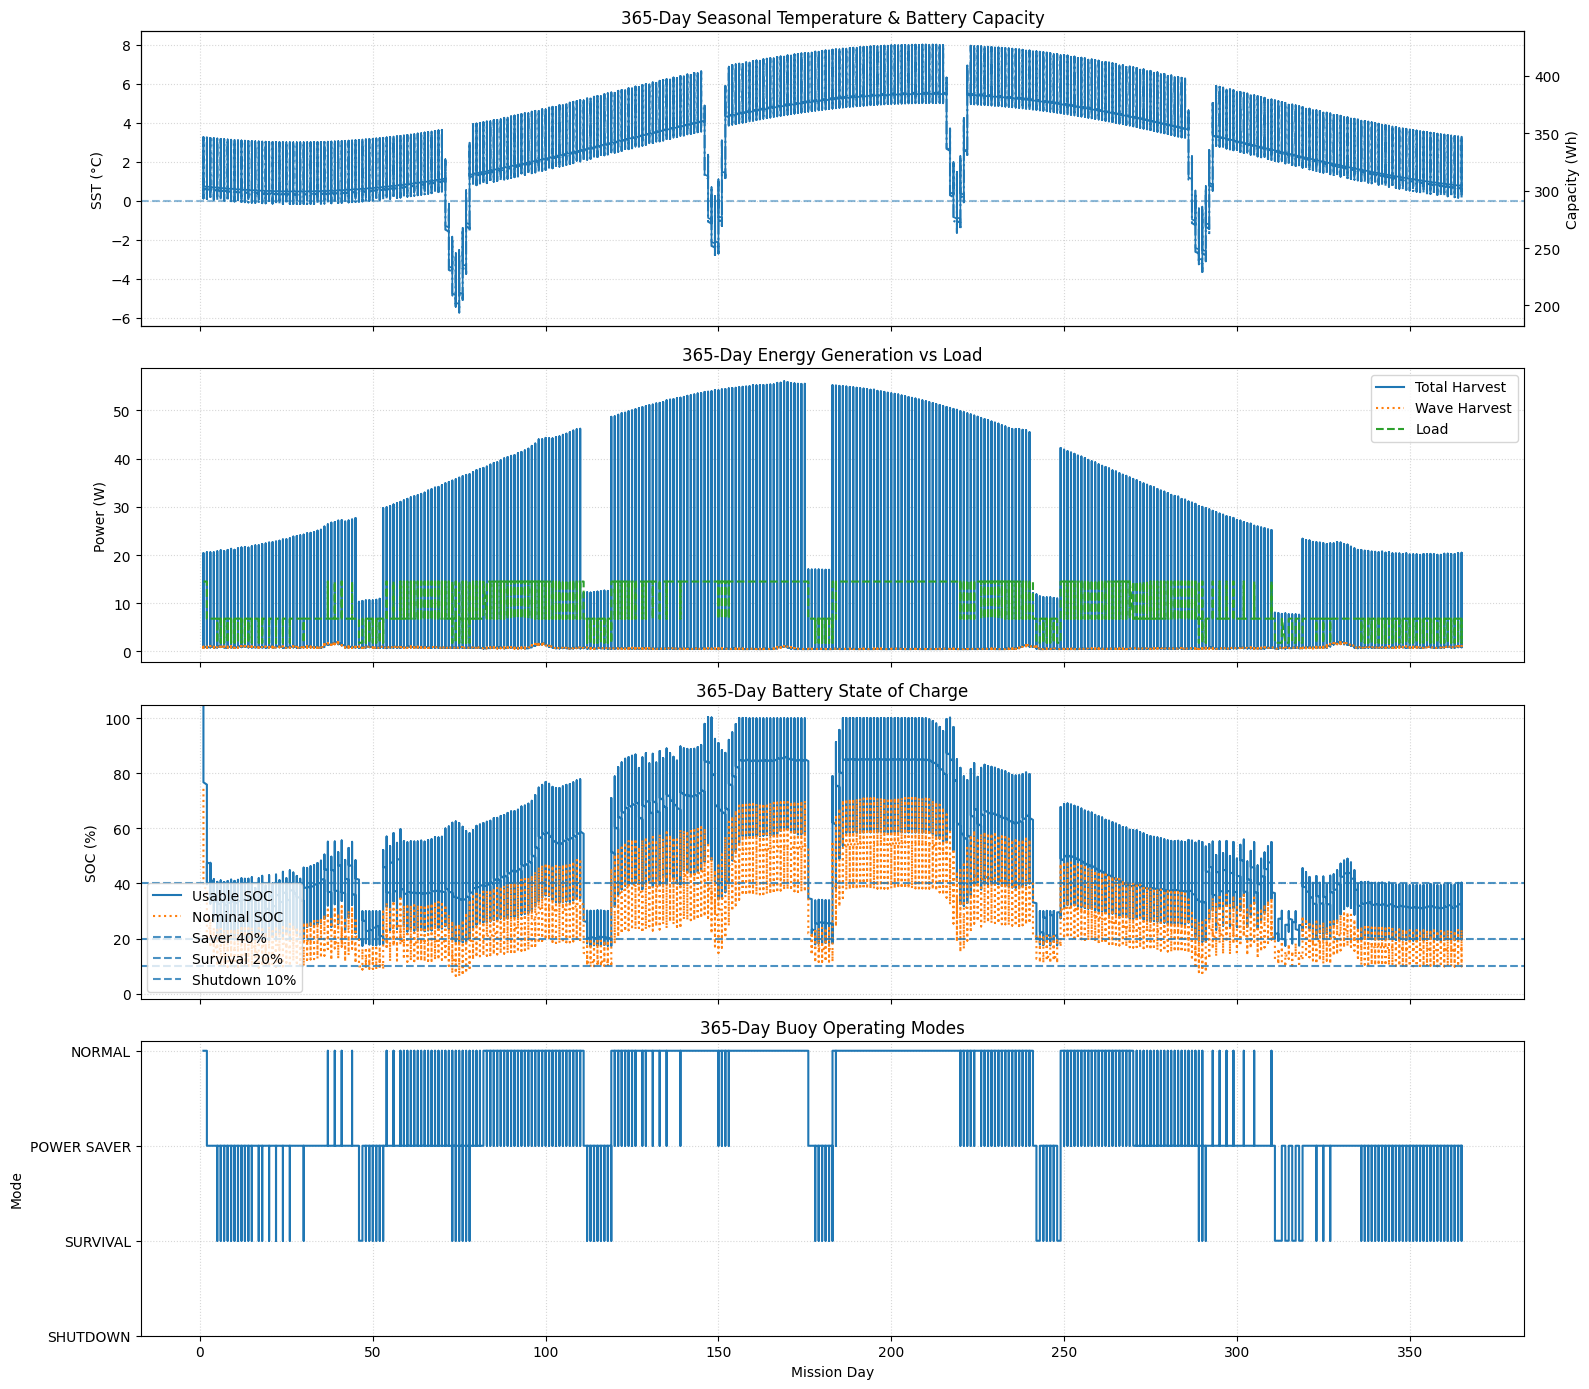



FILES SAVED
1. buoy_365_day_hourly_results.csv
2. buoy_365_day_monthly_summary.csv
3. buoy_365_day_key_metrics.csv


In [3]:
from dataclasses import dataclass, field
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# NumPy 2.0+ backward-compatibility safe integration
_trapezoid = getattr(np, "trapezoid", np.trapz)


# ============================================================
# 1. WAVE SPECTRUM CONFIGURATION
# ============================================================

@dataclass
class WaveSpectrumConfig:
    spectrum_type: str = "JONSWAP"
    hs_nominal: float = 1.8
    tp_nominal: float = 8.0
    gamma: float = 3.3

    buoy_diameter_m: float = 1.2
    relative_capture_width: float = 0.08
    pto_efficiency: float = 0.25
    rho_seawater: float = 1025.0
    g: float = 9.81


# ============================================================
# 2. THERMAL CONFIGURATION
# ============================================================

@dataclass
class ThermalConfig:
    # Annual mean-like baseline
    sst_base_c: float = 4.0

    # Daily temperature variation
    sst_diurnal_amp_c: float = 1.5

    # Temporary cold-event magnitude
    cold_snap_drop_c: float = 6.5

    # Reference battery temperature
    t_nominal_c: float = 25.0


# ============================================================
# 3. BUOY CONFIGURATION
# ============================================================

@dataclass
class BuoyConfig:

    # ---------------- TIME ----------------
    sim_days: int = 365
    dt_hours: float = 0.25

    # ---------------- BATTERY ----------------
    battery_capacity_wh: float = 600.0
    initial_soc: float = 0.75

    base_charge_eff: float = 0.94
    base_discharge_eff: float = 0.96

    self_discharge_daily_pct: float = 0.0005

    # ---------------- SOLAR ----------------
    solar_peak_watts: float = 55.0

    # ---------------- LOAD ----------------
    p_normal: float = 14.5
    p_power_saver: float = 6.8
    p_survival: float = 1.8
    p_shutdown: float = 0.2

    # ---------------- HYSTERESIS ----------------
    soc_drop_to_saver: float = 0.40
    soc_rec_to_normal: float = 0.55

    soc_drop_to_surv: float = 0.20
    soc_rec_to_saver: float = 0.30

    soc_drop_to_shut: float = 0.10
    soc_rec_to_surv: float = 0.18

    # ---------------- SUBSYSTEMS ----------------
    wave: WaveSpectrumConfig = field(
        default_factory=WaveSpectrumConfig
    )

    thermal: ThermalConfig = field(
        default_factory=ThermalConfig
    )


# ============================================================
# 4. BUOY SIMULATION
# ============================================================

class BuoySimulation:

    def __init__(self, cfg: BuoyConfig):

        self.cfg = cfg

        self.n_steps = int(
            self.cfg.sim_days * 24 / self.cfg.dt_hours
        )

        self.time_hours = np.arange(
            self.n_steps
        ) * self.cfg.dt_hours

        self.time_days = self.time_hours / 24.0

    # ========================================================
    # BATTERY TEMPERATURE RETENTION
    # ========================================================

    def _battery_capacity_retention_factor(
        self,
        temp_c: float
    ) -> float:

        retention = 1.0 / (
            1.0 +
            np.exp(
                -0.11 * (temp_c - 2.0)
            )
        )

        retention_25 = 1.0 / (
            1.0 +
            np.exp(
                -0.11 * (25.0 - 2.0)
            )
        )

        return float(
            np.clip(
                retention / retention_25,
                0.25,
                1.0
            )
        )

    # ========================================================
    # WAVE SPECTRAL ENERGY FLUX
    # ========================================================

    def _compute_spectral_wave_flux(
        self,
        hs: float,
        tp: float,
        spec_type: str,
        gamma: float
    ) -> float:

        fp = 1.0 / tp

        f = np.linspace(
            0.04,
            0.80,
            400
        )

        s_pm = (
            (5.0 / 16.0)
            * (hs ** 2)
            * (fp ** 4)
            * (f ** -5)
            * np.exp(
                -1.25 * (fp / f) ** 4
            )
        )

        if spec_type.upper() == "JONSWAP":

            sigma = np.where(
                f <= fp,
                0.07,
                0.09
            )

            peak_shape = np.exp(
                -((f - fp) ** 2)
                /
                (
                    2
                    * (sigma ** 2)
                    * (fp ** 2)
                )
            )

            s_f = (
                s_pm
                *
                (gamma ** peak_shape)
            )

            m0_actual = _trapezoid(
                s_f,
                f
            )

            m0_target = (
                hs / 4.0
            ) ** 2

            s_f *= (
                m0_target
                /
                m0_actual
            )

        else:
            s_f = s_pm

        coeff = (
            self.cfg.wave.rho_seawater
            * self.cfg.wave.g ** 2
        ) / (4.0 * np.pi)

        flux_w_per_meter = (
            coeff
            *
            _trapezoid(
                s_f / f,
                f
            )
        )

        return float(
            flux_w_per_meter
        )

    # ========================================================
    # SEASONAL ENVIRONMENT
    # ========================================================

    def _generate_environmental_inputs(self):

        t_hours = self.time_hours
        day_of_year = (
            t_hours / 24.0
        ) % 365.0

        # ----------------------------------------------------
        # 1. SEASONAL SOLAR
        # ----------------------------------------------------
        #
        # This is a simplified seasonal daylight model.
        # It is a modelling framework, not measured polar
        # irradiance data yet.
        #
        # Seasonal factor:
        #   ~winter minimum
        #   ~summer maximum
        #
        seasonal_solar_factor = (
            0.35
            +
            0.65
            *
            (
                0.5
                +
                0.5
                *
                np.cos(
                    2
                    * np.pi
                    *
                    (day_of_year - 172.0)
                    / 365.0
                )
            )
        )

        # Daily solar cycle
        hour_of_day = (
            t_hours % 24.0
        )

        daily_solar_shape = np.sin(
            np.pi
            *
            (
                hour_of_day - 6.0
            )
            /
            12.0
        )

        daily_solar_shape = np.clip(
            daily_solar_shape,
            0,
            None
        )

        # Cloud events distributed throughout year
        cloud_factor = np.ones(
            self.n_steps
        )

        cloud_events = [
            (45, 52, 0.35),
            (110, 118, 0.25),
            (175, 182, 0.30),
            (240, 248, 0.25),
            (310, 318, 0.30),
        ]

        for start_day, end_day, factor in cloud_events:

            mask = (
                (day_of_year >= start_day)
                &
                (day_of_year <= end_day)
            )

            cloud_factor[mask] = factor

        solar_p = (
            self.cfg.solar_peak_watts
            *
            seasonal_solar_factor
            *
            (daily_solar_shape ** 1.2)
            *
            cloud_factor
        )

        # ----------------------------------------------------
        # 2. SEASONAL SST
        # ----------------------------------------------------

        # Annual temperature cycle
        annual_temp_variation = (
            2.5
            *
            np.cos(
                2
                * np.pi
                *
                (day_of_year - 210.0)
                / 365.0
            )
        )

        # Daily temperature variation
        diurnal_temp = (
            self.cfg.thermal.sst_diurnal_amp_c
            *
            np.cos(
                2
                * np.pi
                *
                (
                    (hour_of_day - 15.0)
                    / 24.0
                )
            )
        )

        # ----------------------------------------------------
        # PERIODIC COLD EVENTS
        # ----------------------------------------------------

        cold_event = np.zeros(
            self.n_steps
        )

        cold_events = [
            (70, 78),
            (145, 152),
            (215, 222),
            (285, 293),
        ]

        for start_day, end_day in cold_events:

            mask = (
                (day_of_year >= start_day)
                &
                (day_of_year <= end_day)
            )

            phase = (
                (
                    day_of_year[mask]
                    - start_day
                )
                /
                (end_day - start_day)
            )

            cold_event[mask] = (
                -self.cfg.thermal.cold_snap_drop_c
                *
                np.sin(
                    np.pi * phase
                )
            )

        sst = (
            self.cfg.thermal.sst_base_c
            +
            annual_temp_variation
            +
            diurnal_temp
            +
            cold_event
        )

        # ----------------------------------------------------
        # 3. SEASONAL WAVE CLIMATE
        # ----------------------------------------------------

        # Simplified seasonal Hs variation.
        # Higher variability during winter/storm season.

        winter_factor = (
            0.5
            +
            0.5
            *
            np.cos(
                2
                * np.pi
                *
                (day_of_year - 20.0)
                / 365.0
            )
        )

        hs_season_factor = (
            0.85
            +
            0.30
            * winter_factor
        )

        hs_t = (
            self.cfg.wave.hs_nominal
            *
            hs_season_factor
        )

        # Add several storm events
        storm_events = [
            (35, 42, 1.35),
            (95, 102, 1.45),
            (165, 172, 1.30),
            (235, 243, 1.50),
            (325, 334, 1.40),
        ]

        for start_day, end_day, storm_factor in storm_events:

            mask = (
                (day_of_year >= start_day)
                &
                (day_of_year <= end_day)
            )

            phase = (
                (
                    day_of_year[mask]
                    - start_day
                )
                /
                (end_day - start_day)
            )

            storm_shape = np.sin(
                np.pi * phase
            )

            hs_t[mask] *= (
                1.0
                +
                (storm_factor - 1.0)
                * storm_shape
            )

        # Wave period changes slightly with sea state
        tp_t = (
            self.cfg.wave.tp_nominal
            *
            (
                hs_t
                /
                self.cfg.wave.hs_nominal
            ) ** 0.25
        )

        # ----------------------------------------------------
        # 4. WAVE HARVESTING
        # ----------------------------------------------------

        effective_capture_width_m = (
            self.cfg.wave.buoy_diameter_m
            *
            self.cfg.wave.relative_capture_width
        )

        # Reproducible stochastic wave envelope
        np.random.seed(42)

        stoch_env = np.ones(
            self.n_steps
        )

        for k in range(
            1,
            self.n_steps
        ):

            random_component = (
                np.random.rayleigh(
                    scale=1.0
                )
            )

            stoch_env[k] = (
                0.95
                * stoch_env[k - 1]
                +
                0.05
                * random_component
            )

        wave_p = np.zeros(
            self.n_steps
        )

        for i in range(
            self.n_steps
        ):

            raw_flux = (
                self._compute_spectral_wave_flux(
                    hs=hs_t[i],
                    tp=tp_t[i],
                    spec_type=self.cfg.wave.spectrum_type,
                    gamma=self.cfg.wave.gamma,
                )
            )

            harvested_watts = (
                raw_flux
                *
                effective_capture_width_m
                *
                self.cfg.wave.pto_efficiency
                *
                0.0025
                *
                stoch_env[i]
            )

            wave_p[i] = np.clip(
                harvested_watts,
                0.5,
                25.0
            )

        return (
            solar_p,
            wave_p,
            hs_t,
            sst
        )

    # ========================================================
    # MAIN BATTERY SIMULATION
    # ========================================================

    def run(self):

        (
            solar_p,
            wave_p,
            hs_t,
            sst
        ) = self._generate_environmental_inputs()

        dt = self.cfg.dt_hours

        soc_derated = np.zeros(
            self.n_steps
        )

        soc_nominal = np.zeros(
            self.n_steps
        )

        stored_energy_wh = np.zeros(
            self.n_steps
        )

        usable_cap_wh = np.zeros(
            self.n_steps
        )

        load_p = np.zeros(
            self.n_steps
        )

        net_p = np.zeros(
            self.n_steps
        )

        modes = []

        current_energy = (
            self.cfg.battery_capacity_wh
            *
            self.cfg.initial_soc
        )

        current_mode = "NORMAL"

        for i in range(
            self.n_steps
        ):

            temp = sst[i]

            retention_factor = (
                self._battery_capacity_retention_factor(
                    temp
                )
            )

            eff_capacity = (
                self.cfg.battery_capacity_wh
                *
                retention_factor
            )

            usable_cap_wh[i] = (
                eff_capacity
            )

            current_usable_soc = np.clip(
                current_energy
                /
                eff_capacity,
                0.0,
                1.0
            )

            # --------------------------------------------
            # Temperature charging penalty
            # --------------------------------------------

            temp_chg_penalty = float(
                np.clip(
                    1.0
                    -
                    max(
                        0.0,
                        (10.0 - temp)
                        * 0.025
                    ),
                    0.50,
                    1.0
                )
            )

            step_charge_eff = (
                self.cfg.base_charge_eff
                *
                temp_chg_penalty
            )

            # --------------------------------------------
            # MODE TRANSITIONS
            # --------------------------------------------

            if current_mode == "NORMAL":

                if (
                    current_usable_soc
                    <
                    self.cfg.soc_drop_to_saver
                ):
                    current_mode = (
                        "POWER_SAVER"
                    )

            elif current_mode == "POWER_SAVER":

                if (
                    current_usable_soc
                    <
                    self.cfg.soc_drop_to_surv
                ):
                    current_mode = (
                        "SURVIVAL"
                    )

                elif (
                    current_usable_soc
                    >
                    self.cfg.soc_rec_to_normal
                ):
                    current_mode = (
                        "NORMAL"
                    )

            elif current_mode == "SURVIVAL":

                if (
                    current_usable_soc
                    <
                    self.cfg.soc_drop_to_shut
                ):
                    current_mode = (
                        "SHUTDOWN"
                    )

                elif (
                    current_usable_soc
                    >
                    self.cfg.soc_rec_to_saver
                ):
                    current_mode = (
                        "POWER_SAVER"
                    )

            elif current_mode == "SHUTDOWN":

                if (
                    current_usable_soc
                    >
                    self.cfg.soc_rec_to_surv
                ):
                    current_mode = (
                        "SURVIVAL"
                    )

            # --------------------------------------------
            # MODE LOAD
            # --------------------------------------------

            if current_mode == "NORMAL":

                p_demand = (
                    self.cfg.p_normal
                )

            elif current_mode == "POWER_SAVER":

                p_demand = (
                    self.cfg.p_power_saver
                )

            elif current_mode == "SURVIVAL":

                p_demand = (
                    self.cfg.p_survival
                )

            else:

                p_demand = (
                    self.cfg.p_shutdown
                )

            # --------------------------------------------
            # ENERGY BALANCE
            # --------------------------------------------

            p_gen = (
                solar_p[i]
                +
                wave_p[i]
            )

            p_net = (
                p_gen
                -
                p_demand
            )

            # Battery self-discharge
            current_energy *= (
                1.0
                -
                (
                    self.cfg.self_discharge_daily_pct
                    *
                    (dt / 24.0)
                )
            )

            # --------------------------------------------
            # CHARGE / DISCHARGE
            # --------------------------------------------

            if p_net >= 0:

                energy_added = (
                    p_net
                    *
                    dt
                    *
                    step_charge_eff
                )

                current_energy = min(
                    eff_capacity,
                    current_energy
                    +
                    energy_added
                )

            else:

                energy_removed = (
                    abs(p_net)
                    *
                    dt
                    /
                    self.cfg.base_discharge_eff
                )

                current_energy = max(
                    0.0,
                    current_energy
                    -
                    energy_removed
                )

            # --------------------------------------------
            # STORE RESULTS
            # --------------------------------------------

            soc_derated[i] = (
                current_energy
                /
                eff_capacity
            )

            soc_nominal[i] = (
                current_energy
                /
                self.cfg.battery_capacity_wh
            )

            stored_energy_wh[i] = (
                current_energy
            )

            modes.append(
                current_mode
            )

            load_p[i] = (
                p_demand
            )

            net_p[i] = (
                p_net
            )

        return pd.DataFrame(
            {
                "hour": self.time_hours,
                "day": (
                    self.time_hours // 24
                ).astype(int) + 1,

                "day_of_year": (
                    self.time_days % 365
                ),

                "sst_c": sst,
                "hs": hs_t,

                "usable_cap_wh":
                    usable_cap_wh,

                "solar_watts":
                    solar_p,

                "wave_watts":
                    wave_p,

                "gen_watts":
                    solar_p + wave_p,

                "load_watts":
                    load_p,

                "net_watts":
                    net_p,

                "soc_usable":
                    soc_derated,

                "soc_nominal":
                    soc_nominal,

                "battery_wh":
                    stored_energy_wh,

                "mode":
                    modes,
            }
        )

    # ========================================================
    # ANNUAL KEY METRICS
    # ========================================================

    def calculate_key_metrics(
        self,
        df
    ):

        dt = self.cfg.dt_hours

        total_solar_wh = (
            df["solar_watts"].sum()
            *
            dt
        )

        total_wave_wh = (
            df["wave_watts"].sum()
            *
            dt
        )

        total_harvested_wh = (
            df["gen_watts"].sum()
            *
            dt
        )

        total_load_wh = (
            df["load_watts"].sum()
            *
            dt
        )

        net_energy_wh = (
            total_harvested_wh
            -
            total_load_wh
        )

        minimum_soc = (
            df["soc_usable"].min()
            *
            100
        )

        final_soc = (
            df["soc_usable"].iloc[-1]
            *
            100
        )

        critical_modes = [
            "SURVIVAL",
            "SHUTDOWN"
        ]

        critical_hours = (
            df["mode"]
            .isin(critical_modes)
            .sum()
            *
            dt
        )

        conservation_hours = (
            (
                df["mode"]
                ==
                "POWER_SAVER"
            )
            .sum()
            *
            dt
        )

        normal_hours = (
            (
                df["mode"]
                ==
                "NORMAL"
            )
            .sum()
            *
            dt
        )

        shutdown_hours = (
            (
                df["mode"]
                ==
                "SHUTDOWN"
            )
            .sum()
            *
            dt
        )

        survival_hours = (
            (
                df["mode"]
                ==
                "SURVIVAL"
            )
            .sum()
            *
            dt
        )

        wave_share = (
            total_wave_wh
            /
            total_harvested_wh
            *
            100
        )

        solar_share = (
            total_solar_wh
            /
            total_harvested_wh
            *
            100
        )

        # Number of critical events
        critical_flag = (
            df["mode"]
            .isin(critical_modes)
        )

        critical_event_count = (
            critical_flag
            &
            ~critical_flag.shift(
                1,
                fill_value=False
            )
        ).sum()

        # Longest continuous critical period
        groups = (
            critical_flag
            !=
            critical_flag.shift(
                1,
                fill_value=False
            )
        ).cumsum()

        critical_lengths = (
            df.loc[
                critical_flag
            ]
            .groupby(groups[critical_flag])
            .size()
        )

        if len(critical_lengths) > 0:
            longest_critical_hours = (
                critical_lengths.max()
                *
                dt
            )
        else:
            longest_critical_hours = 0.0

        # Annual average daily energy
        avg_daily_harvest = (
            total_harvested_wh
            /
            self.cfg.sim_days
        )

        avg_daily_load = (
            total_load_wh
            /
            self.cfg.sim_days
        )

        print("\n")
        print("=" * 75)
        print(
            f"{'365-DAY BUOY PERFORMANCE METRICS':^75}"
        )
        print("=" * 75)

        print(
            f"Simulation duration       : "
            f"{self.cfg.sim_days} days"
        )

        print(
            f"Total solar energy        : "
            f"{total_solar_wh:,.1f} Wh"
        )

        print(
            f"Total wave energy         : "
            f"{total_wave_wh:,.1f} Wh"
        )

        print(
            f"Total harvested energy    : "
            f"{total_harvested_wh:,.1f} Wh"
        )

        print(
            f"Total load energy         : "
            f"{total_load_wh:,.1f} Wh"
        )

        print(
            f"Net energy balance        : "
            f"{net_energy_wh:,.1f} Wh"
        )

        print(
            f"Average daily harvest     : "
            f"{avg_daily_harvest:,.1f} Wh/day"
        )

        print(
            f"Average daily load        : "
            f"{avg_daily_load:,.1f} Wh/day"
        )

        print(
            f"Minimum usable SOC        : "
            f"{minimum_soc:.1f} %"
        )

        print(
            f"Final usable SOC          : "
            f"{final_soc:.1f} %"
        )

        print(
            f"Normal mode               : "
            f"{normal_hours:.1f} h"
        )

        print(
            f"Power-saver mode          : "
            f"{conservation_hours:.1f} h"
        )

        print(
            f"Survival mode             : "
            f"{survival_hours:.1f} h"
        )

        print(
            f"Shutdown mode             : "
            f"{shutdown_hours:.1f} h"
        )

        print(
            f"Critical mode             : "
            f"{critical_hours:.1f} h"
        )

        print(
            f"Critical events           : "
            f"{critical_event_count}"
        )

        print(
            f"Longest critical event   : "
            f"{longest_critical_hours:.1f} h"
        )

        print(
            f"Solar contribution        : "
            f"{solar_share:.1f} %"
        )

        print(
            f"Wave contribution         : "
            f"{wave_share:.1f} %"
        )

        print("=" * 75)

        return {
            "simulation_days":
                self.cfg.sim_days,

            "total_solar_wh":
                total_solar_wh,

            "total_wave_wh":
                total_wave_wh,

            "total_harvested_wh":
                total_harvested_wh,

            "total_load_wh":
                total_load_wh,

            "net_energy_wh":
                net_energy_wh,

            "average_daily_harvest_wh":
                avg_daily_harvest,

            "average_daily_load_wh":
                avg_daily_load,

            "minimum_soc_percent":
                minimum_soc,

            "final_soc_percent":
                final_soc,

            "normal_hours":
                normal_hours,

            "power_saver_hours":
                conservation_hours,

            "survival_hours":
                survival_hours,

            "shutdown_hours":
                shutdown_hours,

            "critical_hours":
                critical_hours,

            "critical_event_count":
                critical_event_count,

            "longest_critical_hours":
                longest_critical_hours,

            "solar_share_percent":
                solar_share,

            "wave_share_percent":
                wave_share,
        }

    # ========================================================
    # MONTHLY SUMMARY
    # ========================================================

    def monthly_summary(
        self,
        df
    ):

        df = df.copy()

        df["month"] = (
            ((df["day"] - 1) // 30) + 1
        )

        # Make exactly 12 calendar-like bins
        df["month"] = np.select(
            [
                df["day"] <= 31,
                df["day"] <= 59,
                df["day"] <= 90,
                df["day"] <= 120,
                df["day"] <= 151,
                df["day"] <= 181,
                df["day"] <= 212,
                df["day"] <= 243,
                df["day"] <= 273,
                df["day"] <= 304,
                df["day"] <= 334,
            ],
            [
                1, 2, 3, 4, 5, 6,
                7, 8, 9, 10, 11
            ],
            default=12
        )

        monthly = (
            df.groupby("month")
            .agg(
                avg_sst_c=(
                    "sst_c",
                    "mean"
                ),

                min_sst_c=(
                    "sst_c",
                    "min"
                ),

                avg_hs_m=(
                    "hs",
                    "mean"
                ),

                min_soc=(
                    "soc_usable",
                    "min"
                ),

                end_soc=(
                    "soc_usable",
                    "last"
                ),

                solar_wh=(
                    "solar_watts",
                    lambda x:
                    np.sum(x)
                    * self.cfg.dt_hours
                ),

                wave_wh=(
                    "wave_watts",
                    lambda x:
                    np.sum(x)
                    * self.cfg.dt_hours
                ),

                load_wh=(
                    "load_watts",
                    lambda x:
                    np.sum(x)
                    * self.cfg.dt_hours
                ),

                critical_hours=(
                    "mode",
                    lambda x:
                    x.isin(
                        [
                            "SURVIVAL",
                            "SHUTDOWN"
                        ]
                    ).sum()
                    * self.cfg.dt_hours
                )
            )
            .reset_index()
        )

        monthly["harvested_wh"] = (
            monthly["solar_wh"]
            +
            monthly["wave_wh"]
        )

        monthly["net_energy_wh"] = (
            monthly["harvested_wh"]
            -
            monthly["load_wh"]
        )

        print("\n")
        print("=" * 115)
        print(
            f"{'MONTHLY ENERGY & SURVIVAL SUMMARY':^115}"
        )
        print("=" * 115)

        print(
            f"{'Month':<7}"
            f"{'Avg SST':<10}"
            f"{'Min SST':<10}"
            f"{'Avg Hs':<10}"
            f"{'Solar Wh':<13}"
            f"{'Wave Wh':<12}"
            f"{'Load Wh':<12}"
            f"{'Net Wh':<12}"
            f"{'Min SOC':<10}"
            f"{'Critical h':<12}"
        )

        print("-" * 115)

        for _, r in monthly.iterrows():

            print(
                f"{int(r['month']):<7}"
                f"{r['avg_sst_c']:<10.2f}"
                f"{r['min_sst_c']:<10.2f}"
                f"{r['avg_hs_m']:<10.2f}"
                f"{r['solar_wh']:<13.1f}"
                f"{r['wave_wh']:<12.1f}"
                f"{r['load_wh']:<12.1f}"
                f"{r['net_energy_wh']:<12.1f}"
                f"{r['min_soc']*100:<10.1f}"
                f"{r['critical_hours']:<12.1f}"
            )

        print("=" * 115)

        return monthly

    # ========================================================
    # PLOTS
    # ========================================================

    def plot_annual_telemetry(
        self,
        df
    ):

        mode_mapping = {
            "SHUTDOWN": 0,
            "SURVIVAL": 1,
            "POWER_SAVER": 2,
            "NORMAL": 3,
        }

        df = df.copy()

        df["mode_code"] = (
            df["mode"].map(
                mode_mapping
            )
        )

        fig, axs = plt.subplots(
            4,
            1,
            figsize=(16, 14),
            sharex=True
        )

        # ----------------------------------------------------
        # 1. SST + BATTERY CAPACITY
        # ----------------------------------------------------

        ax0_twin = axs[0].twinx()

        axs[0].plot(
            df["day"],
            df["sst_c"],
            lw=1.2,
            label="SST"
        )

        axs[0].axhline(
            0,
            ls="--",
            alpha=0.5,
            label="0°C"
        )

        axs[0].set_ylabel(
            "SST (°C)"
        )

        ax0_twin.plot(
            df["day"],
            df["usable_cap_wh"],
            ls="-.",
            lw=1.5,
            label="Usable Battery Capacity"
        )

        ax0_twin.set_ylabel(
            "Capacity (Wh)"
        )

        axs[0].set_title(
            "365-Day Seasonal Temperature & Battery Capacity"
        )

        axs[0].grid(
            True,
            linestyle=":",
            alpha=0.5
        )

        # ----------------------------------------------------
        # 2. ENERGY FLOWS
        # ----------------------------------------------------

        axs[1].plot(
            df["day"],
            df["gen_watts"],
            label="Total Harvest"
        )

        axs[1].plot(
            df["day"],
            df["wave_watts"],
            label="Wave Harvest",
            ls=":"
        )

        axs[1].plot(
            df["day"],
            df["load_watts"],
            label="Load",
            ls="--"
        )

        axs[1].set_ylabel(
            "Power (W)"
        )

        axs[1].set_title(
            "365-Day Energy Generation vs Load"
        )

        axs[1].legend(
            loc="upper right"
        )

        axs[1].grid(
            True,
            linestyle=":",
            alpha=0.5
        )

        # ----------------------------------------------------
        # 3. SOC
        # ----------------------------------------------------

        axs[2].plot(
            df["day"],
            df["soc_usable"] * 100,
            label="Usable SOC",
            lw=1.5
        )

        axs[2].plot(
            df["day"],
            df["soc_nominal"] * 100,
            label="Nominal SOC",
            ls=":"
        )

        axs[2].axhline(
            self.cfg.soc_drop_to_saver * 100,
            ls="--",
            alpha=0.8,
            label="Saver 40%"
        )

        axs[2].axhline(
            self.cfg.soc_drop_to_surv * 100,
            ls="--",
            alpha=0.8,
            label="Survival 20%"
        )

        axs[2].axhline(
            self.cfg.soc_drop_to_shut * 100,
            ls="--",
            alpha=0.8,
            label="Shutdown 10%"
        )

        axs[2].set_ylabel(
            "SOC (%)"
        )

        axs[2].set_ylim(
            -2,
            105
        )

        axs[2].set_title(
            "365-Day Battery State of Charge"
        )

        axs[2].legend(
            loc="lower left"
        )

        axs[2].grid(
            True,
            linestyle=":",
            alpha=0.5
        )

        # ----------------------------------------------------
        # 4. MODES
        # ----------------------------------------------------

        axs[3].step(
            df["day"],
            df["mode_code"],
            where="post",
            lw=1.5
        )

        axs[3].set_yticks(
            [0, 1, 2, 3]
        )

        axs[3].set_yticklabels(
            [
                "SHUTDOWN",
                "SURVIVAL",
                "POWER SAVER",
                "NORMAL"
            ]
        )

        axs[3].set_ylabel(
            "Mode"
        )

        axs[3].set_xlabel(
            "Mission Day"
        )

        axs[3].set_title(
            "365-Day Buoy Operating Modes"
        )

        axs[3].grid(
            True,
            linestyle=":",
            alpha=0.5
        )

        plt.tight_layout()

        plt.show()


# ============================================================
# 5. RUN 365-DAY SIMULATION
# ============================================================

if __name__ == "__main__":

    wave_cfg = WaveSpectrumConfig(
        spectrum_type="JONSWAP",
        hs_nominal=1.6,
        tp_nominal=8.0,
        buoy_diameter_m=1.2,
    )

    thermal_cfg = ThermalConfig(
        sst_base_c=4.0,
        sst_diurnal_amp_c=1.5,
        cold_snap_drop_c=6.5,
    )

    # ========================================================
    # IMPORTANT:
    # 30 DAYS -> 365 DAYS
    # ========================================================

    sim_cfg = BuoyConfig(
        sim_days=365,
        battery_capacity_wh=600.0,
        initial_soc=0.75,
        solar_peak_watts=55.0,
        wave=wave_cfg,
        thermal=thermal_cfg,
    )

    sim = BuoySimulation(
        sim_cfg
    )

    # Run simulation
    results = sim.run()

    # ========================================================
    # ANNUAL KPI
    # ========================================================

    metrics = (
        sim.calculate_key_metrics(
            results
        )
    )

    # ========================================================
    # MONTHLY ANALYSIS
    # ========================================================

    monthly_results = (
        sim.monthly_summary(
            results
        )
    )

    # ========================================================
    # PLOTS
    # ========================================================

    sim.plot_annual_telemetry(
        results
    )

    # ========================================================
    # SAVE DATA FOR FURTHER ANALYSIS
    # ========================================================

    results.to_csv(
        "buoy_365_day_hourly_results.csv",
        index=False
    )

    monthly_results.to_csv(
        "buoy_365_day_monthly_summary.csv",
        index=False
    )

    pd.DataFrame(
        [metrics]
    ).to_csv(
        "buoy_365_day_key_metrics.csv",
        index=False
    )

    print("\n")
    print("=" * 70)
    print("FILES SAVED")
    print("=" * 70)

    print(
        "1. buoy_365_day_hourly_results.csv"
    )

    print(
        "2. buoy_365_day_monthly_summary.csv"
    )

    print(
        "3. buoy_365_day_key_metrics.csv"
    )

    print("=" * 70)


Rows: 35040

Columns:
['hour', 'day', 'day_of_year', 'sst_c', 'hs', 'usable_cap_wh', 'solar_watts', 'wave_watts', 'gen_watts', 'load_watts', 'net_watts', 'soc_usable', 'soc_nominal', 'battery_wh', 'mode']

DAILY ENERGY ANALYSIS
 day   solar_Wh   wave_Wh  harvested_Wh  load_Wh  net_energy_Wh  min_SOC  avg_SST  critical_hours
   1 141.046658 20.337020    161.383679  348.000    -186.616321 0.767844 1.765332            0.00
   2 141.482826 21.157666    162.640492  226.725     -64.084508 0.397435 1.746371            0.00
   3 141.956359 23.358447    165.314806  163.200       2.114806 0.326639 1.728077            0.00
   4 142.467115 20.750311    163.217427  163.200       0.017427 0.262337 1.710458            0.00
   5 143.014945 22.863208    165.878153  140.700      25.178153 0.198093 1.693516            4.50
   6 143.599685 25.337164    168.936848  138.200      30.736848 0.197982 1.677258            5.00
   7 144.221161 19.851970    164.073132  139.450      24.623132 0.198710 1.661688     

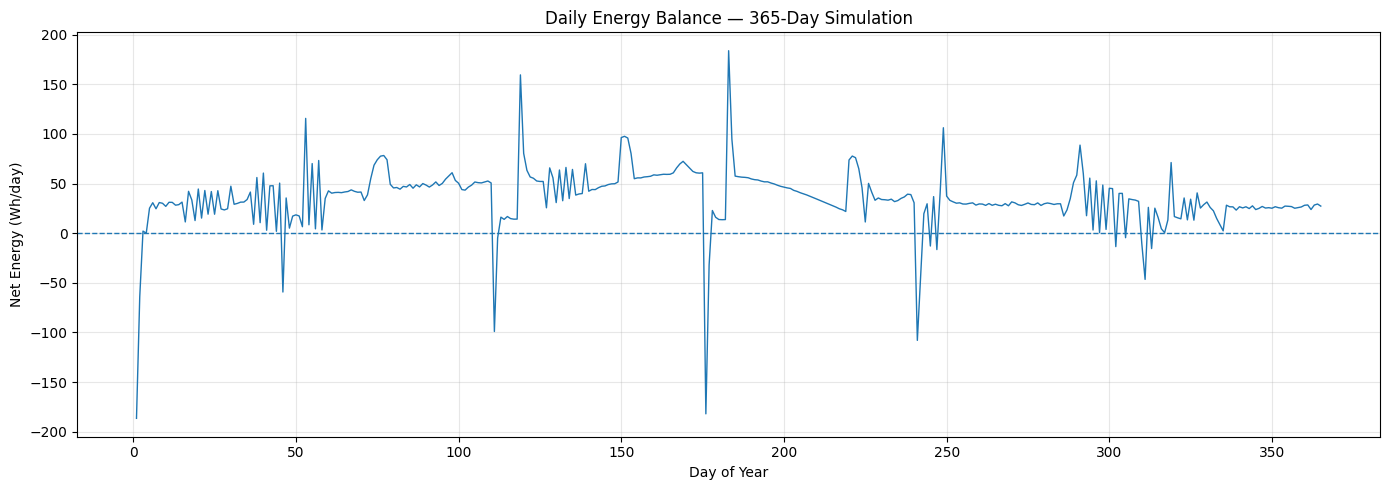

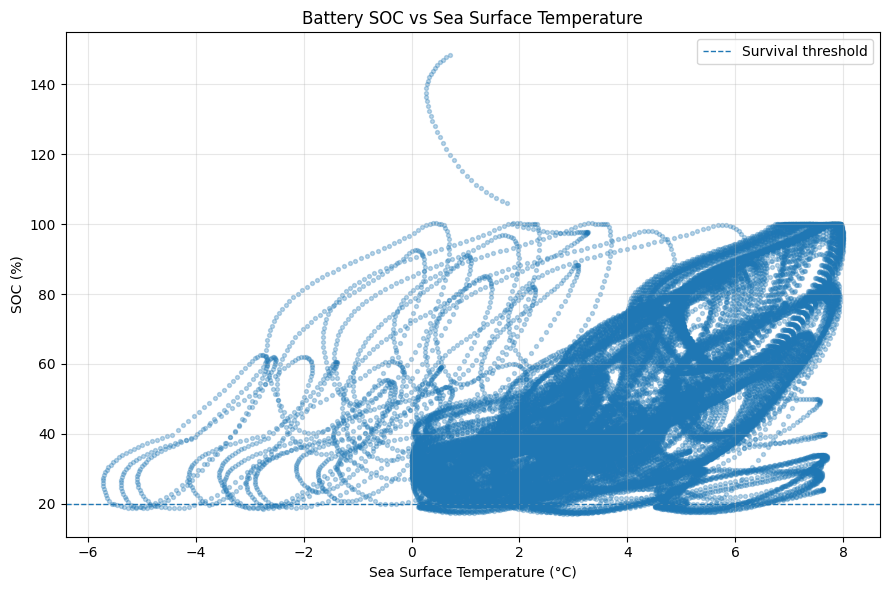

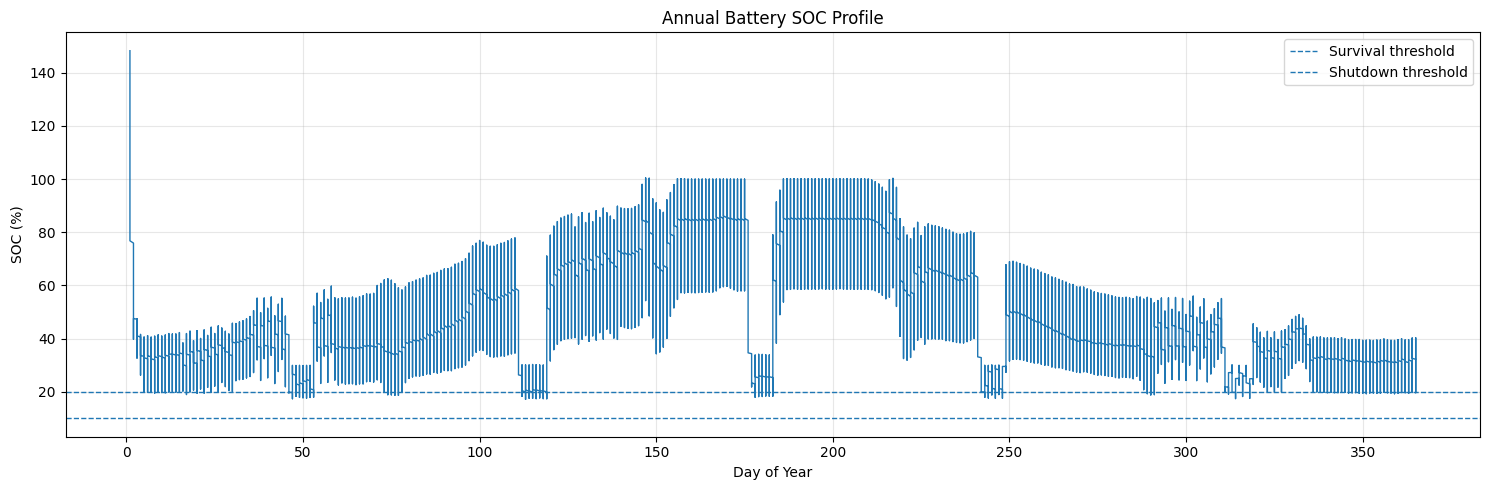

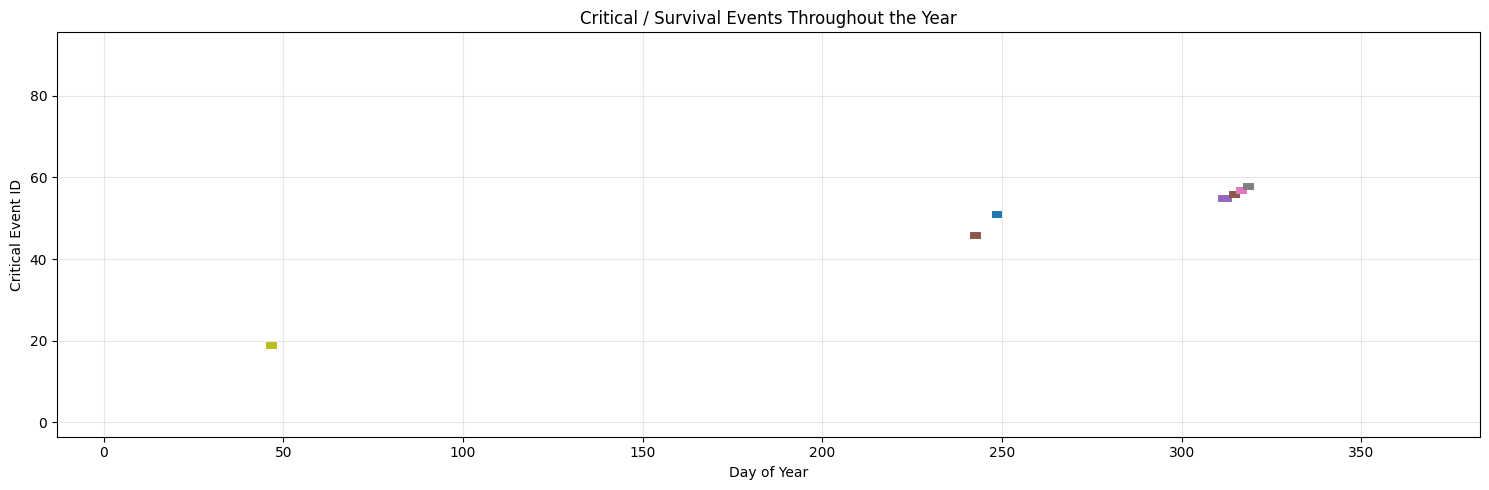

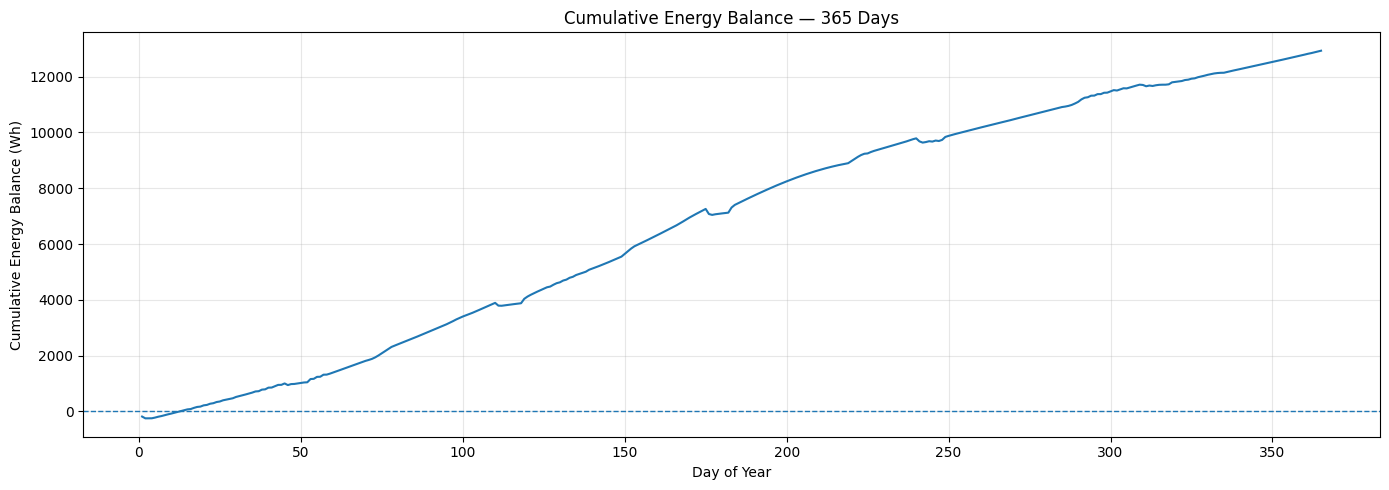


FINAL ENGINEERING DIAGNOSTIC
Annual net energy balance : 12931.1 Wh
Average daily net energy  : 35.43 Wh/day
Days with deficit         : 16
Minimum SOC               : 17.1%
Critical events           : 91
Longest critical event   : 49.0 h
Lowest event SOC         : 17.1%
Total survival hours     : 877.5 h
Total shutdown hours     : 0.0 h
SOC vs SST correlation   : 0.531

Analysis complete.


In [4]:

# ============================================================
# 365-DAY WINTER BOTTLENECK ANALYSIS
# Corrected for the actual results DataFrame columns
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 0. LOAD EXISTING RESULTS
# ------------------------------------------------------------

df = results.copy()

DT_HOURS = 0.25

print("Rows:", len(df))
print("\nColumns:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 1. CONVERT POWER -> ENERGY
# ------------------------------------------------------------

df["solar_Wh"] = df["solar_watts"] * DT_HOURS
df["wave_Wh"]  = df["wave_watts"] * DT_HOURS
df["gen_Wh"]   = df["gen_watts"] * DT_HOURS
df["load_Wh"]  = df["load_watts"] * DT_HOURS

# Rename internally for easier analysis
df["soc"]   = df["soc_usable"]
df["sst_C"] = df["sst_c"]
df["Hs_m"]  = df["hs"]

# Critical condition
df["is_critical"] = df["mode"].isin(
    ["SURVIVAL", "SHUTDOWN"]
)


# ============================================================
# 2. DAILY ENERGY ANALYSIS
# ============================================================

daily = (
    df.groupby(df["day"].astype(int))
      .agg(
          solar_Wh=("solar_Wh", "sum"),
          wave_Wh=("wave_Wh", "sum"),
          harvested_Wh=("gen_Wh", "sum"),
          load_Wh=("load_Wh", "sum"),

          min_SOC=("soc", "min"),
          end_SOC=("soc", "last"),

          avg_SST=("sst_C", "mean"),
          min_SST=("sst_C", "min"),

          avg_Hs=("Hs_m", "mean"),

          critical_hours=(
              "is_critical",
              lambda x: x.sum() * DT_HOURS
          )
      )
      .reset_index()
      .rename(columns={"day": "day"})
)

# Daily energy balance
daily["net_energy_Wh"] = (
    daily["harvested_Wh"]
    -
    daily["load_Wh"]
)

daily["energy_deficit_Wh"] = np.minimum(
    daily["net_energy_Wh"],
    0
)

daily["energy_surplus_Wh"] = np.maximum(
    daily["net_energy_Wh"],
    0
)

daily["cumulative_energy_balance_Wh"] = (
    daily["net_energy_Wh"].cumsum()
)

daily["critical_day"] = (
    daily["critical_hours"] > 0
)


# ============================================================
# 3. DAILY ANALYSIS SUMMARY
# ============================================================

print("\n" + "="*70)
print("DAILY ENERGY ANALYSIS")
print("="*70)

print(
    daily[
        [
            "day",
            "solar_Wh",
            "wave_Wh",
            "harvested_Wh",
            "load_Wh",
            "net_energy_Wh",
            "min_SOC",
            "avg_SST",
            "critical_hours"
        ]
    ].head(15).to_string(index=False)
)

deficit_days = (
    daily["net_energy_Wh"] < 0
).sum()

print("\nDays with energy deficit:", deficit_days)

print(
    "Worst daily deficit:",
    f"{daily['net_energy_Wh'].min():.2f} Wh"
)

print(
    "Total deficit energy:",
    f"{daily['energy_deficit_Wh'].sum():.2f} Wh"
)

print(
    "Total surplus energy:",
    f"{daily['energy_surplus_Wh'].sum():.2f} Wh"
)


# ============================================================
# 4. SOC VS ENVIRONMENT
# ============================================================

corr_soc_temp = df["soc"].corr(
    df["sst_C"]
)

corr_soc_solar = df["soc"].corr(
    df["solar_Wh"]
)

corr_soc_wave = df["soc"].corr(
    df["wave_Wh"]
)

corr_soc_load = df["soc"].corr(
    df["load_Wh"]
)

print("\n" + "="*70)
print("SOC / ENVIRONMENT RELATIONSHIP")
print("="*70)

print(
    f"SOC vs SST       : {corr_soc_temp:.3f}"
)

print(
    f"SOC vs Solar     : {corr_soc_solar:.3f}"
)

print(
    f"SOC vs Wave      : {corr_soc_wave:.3f}"
)

print(
    f"SOC vs Load      : {corr_soc_load:.3f}"
)


# ============================================================
# 5. TEMPERATURE BAND ANALYSIS
# ============================================================

def temperature_band(temp):

    if temp < -2:
        return "< -2 °C"

    elif temp < 0:
        return "-2 to 0 °C"

    elif temp < 2:
        return "0 to 2 °C"

    elif temp < 4:
        return "2 to 4 °C"

    elif temp < 6:
        return "4 to 6 °C"

    else:
        return "> 6 °C"


df["temperature_band"] = (
    df["sst_C"].apply(temperature_band)
)

temp_analysis = (
    df.groupby("temperature_band")
      .agg(
          hours=(
              "soc",
              lambda x: len(x) * DT_HOURS
          ),

          avg_SOC=("soc", "mean"),

          min_SOC=("soc", "min"),

          avg_solar=(
              "solar_Wh",
              "mean"
          ),

          avg_wave=(
              "wave_Wh",
              "mean"
          ),

          critical_hours=(
              "is_critical",
              lambda x: x.sum() * DT_HOURS
          )
      )
      .reset_index()
)

print("\n" + "="*70)
print("TEMPERATURE BAND ANALYSIS")
print("="*70)

print(
    temp_analysis.to_string(index=False)
)


# ============================================================
# 6. CRITICAL EVENT DETECTION
# ============================================================

critical_events = []

in_event = False
start_idx = None

for i in range(len(df)):

    critical = df.loc[i, "is_critical"]

    # --------------------------------------------------------
    # START EVENT
    # --------------------------------------------------------

    if critical and not in_event:

        start_idx = i
        in_event = True


    # --------------------------------------------------------
    # END EVENT
    # --------------------------------------------------------

    elif not critical and in_event:

        end_idx = i - 1

        event = df.loc[
            start_idx:end_idx
        ]

        critical_events.append({

            "event_id":
                len(critical_events) + 1,

            "start_day":
                event["day"].iloc[0],

            "end_day":
                event["day"].iloc[-1],

            "duration_hours":
                len(event) * DT_HOURS,

            "minimum_SOC":
                event["soc"].min(),

            "minimum_SST":
                event["sst_C"].min(),

            "average_SST":
                event["sst_C"].mean(),

            "average_Hs":
                event["Hs_m"].mean(),

            "solar_energy_Wh":
                event["solar_Wh"].sum(),

            "wave_energy_Wh":
                event["wave_Wh"].sum(),

            "load_energy_Wh":
                event["load_Wh"].sum(),

            "net_energy_Wh":
                (
                    event["gen_Wh"].sum()
                    -
                    event["load_Wh"].sum()
                ),

            "survival_hours":
                (
                    event["mode"] == "SURVIVAL"
                ).sum() * DT_HOURS,

            "shutdown_hours":
                (
                    event["mode"] == "SHUTDOWN"
                ).sum() * DT_HOURS
        })

        in_event = False
        start_idx = None


# ------------------------------------------------------------
# HANDLE EVENT AT SIMULATION END
# ------------------------------------------------------------

if in_event:

    event = df.loc[start_idx:]

    critical_events.append({

        "event_id":
            len(critical_events) + 1,

        "start_day":
            event["day"].iloc[0],

        "end_day":
            event["day"].iloc[-1],

        "duration_hours":
            len(event) * DT_HOURS,

        "minimum_SOC":
            event["soc"].min(),

        "minimum_SST":
            event["sst_C"].min(),

        "average_SST":
            event["sst_C"].mean(),

        "average_Hs":
            event["Hs_m"].mean(),

        "solar_energy_Wh":
            event["solar_Wh"].sum(),

        "wave_energy_Wh":
            event["wave_Wh"].sum(),

        "load_energy_Wh":
            event["load_Wh"].sum(),

        "net_energy_Wh":
            (
                event["gen_Wh"].sum()
                -
                event["load_Wh"].sum()
            ),

        "survival_hours":
            (
                event["mode"] == "SURVIVAL"
            ).sum() * DT_HOURS,

        "shutdown_hours":
            (
                event["mode"] == "SHUTDOWN"
            ).sum() * DT_HOURS
    })


critical_events = pd.DataFrame(
    critical_events
)


# ============================================================
# 7. CRITICAL EVENT RESULTS
# ============================================================

print("\n" + "="*70)
print("CRITICAL EVENT ANALYSIS")
print("="*70)

print(
    f"Total critical events: {len(critical_events)}"
)

if len(critical_events) > 0:

    print("\nAll critical events:")

    print(
        critical_events.to_string(
            index=False
        )
    )

    print("\nLongest events:")

    print(
        critical_events
        .sort_values(
            "duration_hours",
            ascending=False
        )
        .head(10)
        .to_string(index=False)
    )

    print("\nLowest SOC events:")

    print(
        critical_events
        .sort_values(
            "minimum_SOC",
            ascending=True
        )
        .head(10)
        .to_string(index=False)
    )


# ============================================================
# 8. PLOT — DAILY NET ENERGY
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    daily["day"],
    daily["net_energy_Wh"],
    linewidth=1
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Day of Year")
plt.ylabel("Net Energy (Wh/day)")
plt.title(
    "Daily Energy Balance — 365-Day Simulation"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 9. PLOT — SOC VS TEMPERATURE
# ============================================================

plt.figure(figsize=(9, 6))

plt.scatter(
    df["sst_C"],
    df["soc"] * 100,
    s=8,
    alpha=0.30
)

plt.axhline(
    20,
    linestyle="--",
    linewidth=1,
    label="Survival threshold"
)

plt.xlabel(
    "Sea Surface Temperature (°C)"
)

plt.ylabel("SOC (%)")

plt.title(
    "Battery SOC vs Sea Surface Temperature"
)

plt.grid(True, alpha=0.3)

plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 10. PLOT — ANNUAL SOC
# ============================================================

plt.figure(figsize=(15, 5))

plt.plot(
    df["day"],
    df["soc"] * 100,
    linewidth=1
)

plt.axhline(
    20,
    linestyle="--",
    linewidth=1,
    label="Survival threshold"
)

plt.axhline(
    10,
    linestyle="--",
    linewidth=1,
    label="Shutdown threshold"
)

plt.xlabel("Day of Year")
plt.ylabel("SOC (%)")

plt.title(
    "Annual Battery SOC Profile"
)

plt.grid(True, alpha=0.3)

plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 11. PLOT — CRITICAL EVENT TIMELINE
# ============================================================

plt.figure(figsize=(15, 5))

if len(critical_events) > 0:

    for _, event in critical_events.iterrows():

        plt.plot(
            [
                event["start_day"],
                event["end_day"]
            ],
            [
                event["event_id"],
                event["event_id"]
            ],
            linewidth=5
        )

plt.xlabel("Day of Year")

plt.ylabel("Critical Event ID")

plt.title(
    "Critical / Survival Events Throughout the Year"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 12. PLOT — CUMULATIVE ENERGY BALANCE
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    daily["day"],
    daily["cumulative_energy_balance_Wh"],
    linewidth=1.5
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Day of Year")

plt.ylabel(
    "Cumulative Energy Balance (Wh)"
)

plt.title(
    "Cumulative Energy Balance — 365 Days"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 13. SAVE RESULTS
# ============================================================

daily.to_csv(
    "buoy_365_day_daily_analysis.csv",
    index=False
)

critical_events.to_csv(
    "buoy_365_day_critical_events.csv",
    index=False
)

temp_analysis.to_csv(
    "buoy_365_day_temperature_analysis.csv",
    index=False
)


# ============================================================
# 14. FINAL ENGINEERING DIAGNOSTIC
# ============================================================

print("\n" + "="*70)
print("FINAL ENGINEERING DIAGNOSTIC")
print("="*70)

print(
    f"Annual net energy balance : "
    f"{daily['net_energy_Wh'].sum():.1f} Wh"
)

print(
    f"Average daily net energy  : "
    f"{daily['net_energy_Wh'].mean():.2f} Wh/day"
)

print(
    f"Days with deficit         : "
    f"{deficit_days}"
)

print(
    f"Minimum SOC               : "
    f"{df['soc'].min()*100:.1f}%"
)

print(
    f"Critical events           : "
    f"{len(critical_events)}"
)

if len(critical_events) > 0:

    print(
        f"Longest critical event   : "
        f"{critical_events['duration_hours'].max():.1f} h"
    )

    print(
        f"Lowest event SOC         : "
        f"{critical_events['minimum_SOC'].min()*100:.1f}%"
    )

    print(
        f"Total survival hours     : "
        f"{critical_events['survival_hours'].sum():.1f} h"
    )

    print(
        f"Total shutdown hours     : "
        f"{critical_events['shutdown_hours'].sum():.1f} h"
    )

print(
    f"SOC vs SST correlation   : "
    f"{corr_soc_temp:.3f}"
)

print("\nAnalysis complete.")


In [5]:
print("Results created:", "results" in globals())

if "results" in globals():
    print("Rows:", len(results))
    print(results.head())

Results created: True
Rows: 35040
   hour  day  day_of_year     sst_c        hs  usable_cap_wh  solar_watts  \
0  0.00    1     0.000000  0.714271  1.825916     301.031350          0.0   
1  0.25    1     0.010417  0.646967  1.825931     299.838666          0.0   
2  0.50    1     0.020833  0.584492  1.825945     298.732148          0.0   
3  0.75    1     0.031250  0.527114  1.825960     297.716407          0.0   
4  1.00    1     0.041667  0.475076  1.825974     296.795659          0.0   

   wave_watts  gen_watts  load_watts  net_watts  soc_usable  soc_nominal  \
0    0.733274   0.733274        14.5 -13.766726    1.482944     0.744021   
1    0.732142   0.732142        14.5 -13.767858    1.476877     0.738041   
2    0.785510   0.785510        14.5 -13.714490    1.470384     0.732085   
3    0.805749   0.805749        14.5 -13.694251    1.463415     0.726138   
4    0.815020   0.815020        14.5 -13.684980    1.455939     0.720194   

   battery_wh    mode  
0  446.412571  NORMAL 

In [6]:
# ============================================================
# SAVE 365-DAY SIMULATION RESULTS
# ============================================================

# Save full timestep data
results.to_csv("buoy_365_day_hourly_results.csv", index=False)

# Create monthly summary
results["month"] = ((results["day"] - 1) // 30) + 1
results.loc[results["month"] > 12, "month"] = 12

monthly_summary = (
    results.groupby("month")
    .agg(
        avg_sst_c=("sst_c", "mean"),
        min_usable_cap_wh=("usable_cap_wh", "min"),
        solar_wh=("solar_watts", lambda x: x.sum() * sim.cfg.dt_hours),
        wave_wh=("wave_watts", lambda x: x.sum() * sim.cfg.dt_hours),
        load_wh=("load_watts", lambda x: x.sum() * sim.cfg.dt_hours),
        min_soc=("soc_usable", "min"),
        end_soc=("soc_usable", "last"),
    )
    .reset_index()
)

monthly_summary.to_csv(
    "buoy_365_day_monthly_summary.csv",
    index=False
)

# Save key metrics
metrics_df = pd.DataFrame([metrics])
metrics_df.to_csv(
    "buoy_365_day_key_metrics.csv",
    index=False
)

print("✅ Files saved successfully")
print("Rows:", len(results))
print("Columns:", list(results.columns))
print("\nFiles:")
print("1. buoy_365_day_hourly_results.csv")
print("2. buoy_365_day_monthly_summary.csv")
print("3. buoy_365_day_key_metrics.csv")

✅ Files saved successfully
Rows: 35040
Columns: ['hour', 'day', 'day_of_year', 'sst_c', 'hs', 'usable_cap_wh', 'solar_watts', 'wave_watts', 'gen_watts', 'load_watts', 'net_watts', 'soc_usable', 'soc_nominal', 'battery_wh', 'mode', 'month']

Files:
1. buoy_365_day_hourly_results.csv
2. buoy_365_day_monthly_summary.csv
3. buoy_365_day_key_metrics.csv


In [7]:
print("results exists:", "results" in globals())
print("Rows:", len(results))
print(results.head())
print(results.tail())

results exists: True
Rows: 35040
   hour  day  day_of_year     sst_c        hs  usable_cap_wh  solar_watts  \
0  0.00    1     0.000000  0.714271  1.825916     301.031350          0.0   
1  0.25    1     0.010417  0.646967  1.825931     299.838666          0.0   
2  0.50    1     0.020833  0.584492  1.825945     298.732148          0.0   
3  0.75    1     0.031250  0.527114  1.825960     297.716407          0.0   
4  1.00    1     0.041667  0.475076  1.825974     296.795659          0.0   

   wave_watts  gen_watts  load_watts  net_watts  soc_usable  soc_nominal  \
0    0.733274   0.733274        14.5 -13.766726    1.482944     0.744021   
1    0.732142   0.732142        14.5 -13.767858    1.476877     0.738041   
2    0.785510   0.785510        14.5 -13.714490    1.470384     0.732085   
3    0.805749   0.805749        14.5 -13.694251    1.463415     0.726138   
4    0.815020   0.815020        14.5 -13.684980    1.455939     0.720194   

   battery_wh    mode  month  
0  446.412571  N

In [8]:
# ============================================================
# SOC CONSISTENCY CHECK
# ============================================================

print("Maximum usable SOC:", results["soc_usable"].max())
print("Minimum usable SOC:", results["soc_usable"].min())

print("\nMaximum nominal SOC:", results["soc_nominal"].max())
print("Minimum nominal SOC:", results["soc_nominal"].min())

print("\nRows where usable SOC > 100%:",
      (results["soc_usable"] > 1.0).sum())

print("\nMaximum usable capacity:",
      results["usable_cap_wh"].max())

print("Minimum usable capacity:",
      results["usable_cap_wh"].min())

print("\nInitial battery energy:",
      results["battery_wh"].iloc[0])

print("Initial usable capacity:",
      results["usable_cap_wh"].iloc[0])

Maximum usable SOC: 1.482943792433638
Minimum usable SOC: 0.17130121104635215

Maximum nominal SOC: 0.7440209522271135
Minimum nominal SOC: 0.06337647457220895

Rows where usable SOC > 100%: 105

Maximum usable capacity: 427.0650212773048
Minimum usable capacity: 193.94173186782692

Initial battery energy: 446.4125713362681
Initial usable capacity: 301.03134968026455


In [9]:
# ============================================================
# CORRECTED 365-DAY BATTERY/SOC MODEL
# ============================================================

class BuoySimulationCorrected:

    def __init__(self, cfg):
        self.cfg = cfg

        self.n_steps = int(
            self.cfg.sim_days * 24 / self.cfg.dt_hours
        )

        self.time_hours = np.linspace(
            0,
            self.cfg.sim_days * 24,
            self.n_steps,
            endpoint=False
        )

    # --------------------------------------------------------
    # Temperature-dependent battery capacity retention
    # --------------------------------------------------------
    def _battery_capacity_retention_factor(self, temp_c):

        retention = 1.0 / (
            1.0 + np.exp(-0.11 * (temp_c - 2.0))
        )

        retention_25 = 1.0 / (
            1.0 + np.exp(-0.11 * (25.0 - 2.0))
        )

        return float(
            np.clip(
                retention / retention_25,
                0.25,
                1.0
            )
        )

    # --------------------------------------------------------
    # Wave energy flux
    # --------------------------------------------------------
    def _compute_spectral_wave_flux(
        self,
        hs,
        tp,
        spec_type,
        gamma
    ):

        fp = 1.0 / tp

        f = np.linspace(
            0.04,
            0.80,
            400
        )

        s_pm = (
            (5.0 / 16.0)
            * (hs ** 2)
            * (fp ** 4)
            * (f ** -5)
            * np.exp(
                -1.25 * (fp / f) ** 4
            )
        )

        if spec_type.upper() == "JONSWAP":

            sigma = np.where(
                f <= fp,
                0.07,
                0.09
            )

            peak_shape = np.exp(
                -(
                    (f - fp) ** 2
                )
                /
                (
                    2
                    * (sigma ** 2)
                    * (fp ** 2)
                )
            )

            s_f = s_pm * (
                gamma ** peak_shape
            )

            m0_actual = _trapezoid(
                s_f,
                f
            )

            m0_target = (
                hs / 4.0
            ) ** 2

            s_f = s_f * (
                m0_target / m0_actual
            )

        else:
            s_f = s_pm

        coeff = (
            self.cfg.wave.rho_seawater
            * (self.cfg.wave.g ** 2)
        ) / (4.0 * np.pi)

        flux_w_per_meter = (
            coeff
            * _trapezoid(
                s_f / f,
                f
            )
        )

        return float(
            flux_w_per_meter
        )

    # --------------------------------------------------------
    # Environmental model
    # --------------------------------------------------------
    def _generate_environmental_inputs(self):

        t_hours = self.time_hours

        # ---------- SST ----------
        diurnal_temp = (
            self.cfg.thermal.sst_diurnal_amp_c
            * np.cos(
                2 * np.pi
                * ((t_hours % 24) - 15.0)
                / 24.0
            )
        )

        cold_event = np.zeros(
            self.n_steps
        )

        upwell_mask = (
            (t_hours >= 72)
            &
            (t_hours <= 132)
        )

        cold_event[upwell_mask] = (
            -self.cfg.thermal.cold_snap_drop_c
            * np.sin(
                np.pi
                * (
                    t_hours[upwell_mask] - 72
                )
                / 60.0
            )
        )

        sst = (
            self.cfg.thermal.sst_base_c
            + diurnal_temp
            + cold_event
        )

        # ---------- Solar ----------
        t_day = (
            (t_hours % 24)
            / 24.0
        )

        solar_elevation = np.clip(
            np.sin(
                np.pi
                * (t_day - 0.25)
                / 0.5
            ),
            0,
            1
        )

        cloud_factor = np.ones(
            self.n_steps
        )

        cloud_factor[
            (t_hours >= 48)
            &
            (t_hours <= 120)
        ] = 0.20

        solar_p = (
            self.cfg.solar_peak_watts
            * (solar_elevation ** 1.2)
            * cloud_factor
        )

        # ---------- Wave ----------
        storm_envelope = (
            1.0
            + 0.6
            * np.exp(
                -(
                    (t_hours - 60) ** 2
                )
                /
                (2 * (20 ** 2))
            )
        )

        hs_t = (
            self.cfg.wave.hs_nominal
            * storm_envelope
        )

        tp_t = (
            self.cfg.wave.tp_nominal
            * (storm_envelope ** 0.25)
        )

        effective_capture_width_m = (
            self.cfg.wave.buoy_diameter_m
            * self.cfg.wave.relative_capture_width
        )

        np.random.seed(42)

        stoch_env = np.ones(
            self.n_steps
        )

        for k in range(1, self.n_steps):

            stoch_env[k] = (
                0.95 * stoch_env[k - 1]
                + 0.05
                * np.random.rayleigh(
                    scale=1.0
                )
            )

        wave_p = np.zeros(
            self.n_steps
        )

        for i in range(self.n_steps):

            raw_flux = (
                self._compute_spectral_wave_flux(
                    hs=hs_t[i],
                    tp=tp_t[i],
                    spec_type=self.cfg.wave.spectrum_type,
                    gamma=self.cfg.wave.gamma
                )
            )

            harvested_watts = (
                raw_flux
                * effective_capture_width_m
                * self.cfg.wave.pto_efficiency
                * 0.0025
                * stoch_env[i]
            )

            wave_p[i] = np.clip(
                harvested_watts,
                0.5,
                25.0
            )

        return (
            solar_p,
            wave_p,
            hs_t,
            sst
        )

    # ========================================================
    # CORRECTED RUN
    # ========================================================

    def run(self):

        solar_p, wave_p, hs_t, sst = (
            self._generate_environmental_inputs()
        )

        dt = self.cfg.dt_hours

        soc_usable = np.zeros(
            self.n_steps
        )

        soc_nominal = np.zeros(
            self.n_steps
        )

        battery_wh = np.zeros(
            self.n_steps
        )

        usable_cap_wh = np.zeros(
            self.n_steps
        )

        load_p = np.zeros(
            self.n_steps
        )

        net_p = np.zeros(
            self.n_steps
        )

        modes = []

        # ----------------------------------------------------
        # IMPORTANT:
        # Track nominal battery SOC.
        # Temperature changes usable capacity,
        # NOT the underlying nominal SOC directly.
        # ----------------------------------------------------

        current_soc_nominal = (
            self.cfg.initial_soc
        )

        current_mode = "NORMAL"

        for i in range(self.n_steps):

            temp = sst[i]

            # Temperature derating
            retention_factor = (
                self._battery_capacity_retention_factor(
                    temp
                )
            )

            eff_capacity = (
                self.cfg.battery_capacity_wh
                * retention_factor
            )

            usable_cap_wh[i] = eff_capacity

            # ----------------------------------------------
            # Usable energy at current temperature
            # ----------------------------------------------

            usable_energy = (
                current_soc_nominal
                * eff_capacity
            )

            current_usable_soc = np.clip(
                current_soc_nominal,
                0.0,
                1.0
            )

            # ----------------------------------------------
            # Temperature charging penalty
            # ----------------------------------------------

            temp_chg_penalty = float(
                np.clip(
                    1.0
                    - max(
                        0.0,
                        (10.0 - temp)
                        * 0.025
                    ),
                    0.50,
                    1.0
                )
            )

            step_charge_eff = (
                self.cfg.base_charge_eff
                * temp_chg_penalty
            )

            # ----------------------------------------------
            # State transitions
            # ----------------------------------------------

            if current_mode == "NORMAL":

                if (
                    current_usable_soc
                    < self.cfg.soc_drop_to_saver
                ):
                    current_mode = "POWER_SAVER"

            elif current_mode == "POWER_SAVER":

                if (
                    current_usable_soc
                    < self.cfg.soc_drop_to_surv
                ):
                    current_mode = "SURVIVAL"

                elif (
                    current_usable_soc
                    > self.cfg.soc_rec_to_normal
                ):
                    current_mode = "NORMAL"

            elif current_mode == "SURVIVAL":

                if (
                    current_usable_soc
                    < self.cfg.soc_drop_to_shut
                ):
                    current_mode = "SHUTDOWN"

                elif (
                    current_usable_soc
                    > self.cfg.soc_rec_to_saver
                ):
                    current_mode = "POWER_SAVER"

            elif current_mode == "SHUTDOWN":

                if (
                    current_usable_soc
                    > self.cfg.soc_rec_to_surv
                ):
                    current_mode = "SURVIVAL"

            # ----------------------------------------------
            # Load
            # ----------------------------------------------

            if current_mode == "NORMAL":

                p_demand = self.cfg.p_normal

            elif current_mode == "POWER_SAVER":

                p_demand = self.cfg.p_power_saver

            elif current_mode == "SURVIVAL":

                p_demand = self.cfg.p_survival

            else:

                p_demand = self.cfg.p_shutdown

            # ----------------------------------------------
            # Energy balance
            # ----------------------------------------------

            p_gen = (
                solar_p[i]
                + wave_p[i]
            )

            p_net = (
                p_gen
                - p_demand
            )

            # Self discharge
            current_soc_nominal *= (
                1.0
                - (
                    self.cfg.self_discharge_daily_pct
                    * (dt / 24.0)
                )
            )

            # ----------------------------------------------
            # Charging
            # ----------------------------------------------

            if p_net >= 0:

                energy_added = (
                    p_net
                    * dt
                    * step_charge_eff
                )

                current_soc_nominal += (
                    energy_added
                    / self.cfg.battery_capacity_wh
                )

            # ----------------------------------------------
            # Discharging
            # ----------------------------------------------

            else:

                energy_removed = (
                    abs(p_net)
                    * dt
                    / self.cfg.base_discharge_eff
                )

                current_soc_nominal -= (
                    energy_removed
                    / eff_capacity
                )

            # Keep nominal SOC physically valid
            current_soc_nominal = np.clip(
                current_soc_nominal,
                0.0,
                1.0
            )

            # ----------------------------------------------
            # Store outputs
            # ----------------------------------------------

            usable_energy = (
                current_soc_nominal
                * eff_capacity
            )

            soc_usable[i] = np.clip(
                usable_energy / eff_capacity,
                0.0,
                1.0
            )

            soc_nominal[i] = (
                current_soc_nominal
            )

            battery_wh[i] = (
                current_soc_nominal
                * self.cfg.battery_capacity_wh
            )

            modes.append(
                current_mode
            )

            load_p[i] = p_demand
            net_p[i] = p_net

        return pd.DataFrame({

            "hour": self.time_hours,

            "day": (
                self.time_hours // 24
            ).astype(int) + 1,

            "sst_c": sst,

            "hs": hs_t,

            "usable_cap_wh":
                usable_cap_wh,

            "solar_watts":
                solar_p,

            "wave_watts":
                wave_p,

            "gen_watts":
                solar_p + wave_p,

            "load_watts":
                load_p,

            "net_watts":
                net_p,

            "soc_usable":
                soc_usable,

            "soc_nominal":
                soc_nominal,

            "battery_wh":
                battery_wh,

            "mode":
                modes
        })

In [10]:
# ============================================================
# RUN CORRECTED 365-DAY MODEL
# ============================================================

sim_corrected = BuoySimulationCorrected(sim_cfg)

results = sim_corrected.run()

print("✅ Corrected simulation completed")
print("Rows:", len(results))
print("Maximum usable SOC:",
      results["soc_usable"].max())
print("Minimum usable SOC:",
      results["soc_usable"].min())

✅ Corrected simulation completed
Rows: 35040
Maximum usable SOC: 0.7980028796593154
Minimum usable SOC: 0.1607841436271588


In [11]:
# ============================================================
# CORRECTED MODEL SANITY CHECK
# ============================================================

print("=" * 60)
print("CORRECTED 365-DAY MODEL CHECK")
print("=" * 60)

dt = sim_cfg.dt_hours

total_solar = results["solar_watts"].sum() * dt
total_wave = results["wave_watts"].sum() * dt
total_generation = results["gen_watts"].sum() * dt
total_load = results["load_watts"].sum() * dt

net_energy = total_generation - total_load

normal_hours = (
    results["mode"] == "NORMAL"
).sum() * dt

saver_hours = (
    results["mode"] == "POWER_SAVER"
).sum() * dt

survival_hours = (
    results["mode"] == "SURVIVAL"
).sum() * dt

shutdown_hours = (
    results["mode"] == "SHUTDOWN"
).sum() * dt

critical_hours = (
    results["mode"].isin(
        ["SURVIVAL", "SHUTDOWN"]
    )
).sum() * dt

print(f"Solar energy       : {total_solar:,.1f} Wh")
print(f"Wave energy        : {total_wave:,.1f} Wh")
print(f"Total generation   : {total_generation:,.1f} Wh")
print(f"Total load         : {total_load:,.1f} Wh")
print(f"Net energy         : {net_energy:,.1f} Wh")

print()
print(f"Minimum SOC        : {results['soc_usable'].min()*100:.2f}%")
print(f"Final SOC          : {results['soc_usable'].iloc[-1]*100:.2f}%")

print()
print(f"NORMAL hours       : {normal_hours:.1f}")
print(f"POWER SAVER hours  : {saver_hours:.1f}")
print(f"SURVIVAL hours     : {survival_hours:.1f}")
print(f"SHUTDOWN hours     : {shutdown_hours:.1f}")
print(f"CRITICAL hours     : {critical_hours:.1f}")

print()
print("SOC > 100%:",
      (results["soc_usable"] > 1.0).sum())

print("SOC < 0%:",
      (results["soc_usable"] < 0.0).sum())

print("=" * 60)

CORRECTED 365-DAY MODEL CHECK
Solar energy       : 143,738.4 Wh
Wave energy        : 6,035.8 Wh
Total generation   : 149,774.3 Wh
Total load         : 92,402.1 Wh
Net energy         : 57,372.2 Wh

Minimum SOC        : 16.08%
Final SOC          : 43.02%

NORMAL hours       : 4295.5
POWER SAVER hours  : 4416.2
SURVIVAL hours     : 48.2
SHUTDOWN hours     : 0.0
CRITICAL hours     : 48.2

SOC > 100%: 0
SOC < 0%: 0


In [12]:
# ============================================================
# CORRECTED MODEL — SURVIVAL EVENT ANALYSIS
# ============================================================

DT_HOURS = 0.25

df = results.copy()

# Identify critical operation
df["critical"] = df["mode"].isin(["SURVIVAL", "SHUTDOWN"])

# Find continuous critical events
events = []
in_event = False

for i, row in df.iterrows():

    if row["critical"] and not in_event:
        start_idx = i
        in_event = True

    elif not row["critical"] and in_event:
        end_idx = i - 1
        in_event = False

        event = df.loc[start_idx:end_idx]

        events.append({
            "start_day": event["day"].iloc[0],
            "end_day": event["day"].iloc[-1],
            "duration_h": len(event) * DT_HOURS,
            "min_soc": event["soc_usable"].min(),
            "avg_soc": event["soc_usable"].mean(),
            "min_temp": event["sst_c"].min(),
            "avg_temp": event["sst_c"].mean(),
            "solar_Wh": event["solar_watts"].sum() * DT_HOURS,
            "wave_Wh": event["wave_watts"].sum() * DT_HOURS,
            "load_Wh": event["load_watts"].sum() * DT_HOURS,
            "net_Wh": event["net_watts"].sum() * DT_HOURS
        })

# Handle event continuing until final timestep
if in_event:
    event = df.loc[start_idx:]

    events.append({
        "start_day": event["day"].iloc[0],
        "end_day": event["day"].iloc[-1],
        "duration_h": len(event) * DT_HOURS,
        "min_soc": event["soc_usable"].min(),
        "avg_soc": event["soc_usable"].mean(),
        "min_temp": event["sst_c"].min(),
        "avg_temp": event["sst_c"].mean(),
        "solar_Wh": event["solar_watts"].sum() * DT_HOURS,
        "wave_Wh": event["wave_watts"].sum() * DT_HOURS,
        "load_Wh": event["load_watts"].sum() * DT_HOURS,
        "net_Wh": event["net_watts"].sum() * DT_HOURS
    })

events_df = pd.DataFrame(events)

print("=" * 80)
print("CORRECTED MODEL — SURVIVAL EVENTS")
print("=" * 80)

print(f"Number of survival events : {len(events_df)}")
print(f"Total survival hours     : {events_df['duration_h'].sum():.2f}")
print(f"Longest event            : {events_df['duration_h'].max():.2f} h")
print(f"Lowest SOC event         : {events_df['min_soc'].min()*100:.2f}%")

print()
print("TOP SURVIVAL EVENTS")
print("=" * 80)

print(
    events_df.sort_values(
        "duration_h",
        ascending=False
    ).head(15).to_string(index=False)
)

CORRECTED MODEL — SURVIVAL EVENTS
Number of survival events : 2
Total survival hours     : 48.25
Longest event            : 35.00 h
Lowest SOC event         : 16.08%

TOP SURVIVAL EVENTS
 start_day  end_day  duration_h  min_soc  avg_soc  min_temp  avg_temp   solar_Wh   wave_Wh  load_Wh     net_Wh
         4        5       35.00 0.195940 0.249494 -3.931559 -1.042523 148.945324 33.801836    63.00 119.747160
         5        6       13.25 0.160784 0.190380 -0.881264  0.584533 124.504213 10.138044    23.85 110.792257


In [13]:
# ============================================================
# FIRST SURVIVAL EVENT — DETAILED TRACE
# ============================================================

event = results[
    (results["day"] >= 4) &
    (results["day"] <= 6)
].copy()

event["solar_Wh"] = event["solar_watts"] * sim_cfg.dt_hours
event["wave_Wh"] = event["wave_watts"] * sim_cfg.dt_hours
event["load_Wh"] = event["load_watts"] * sim_cfg.dt_hours
event["net_Wh"] = event["net_watts"] * sim_cfg.dt_hours

print("=" * 100)
print("DAYS 4–6 DETAILED ENERGY / SOC TRACE")
print("=" * 100)

print(
    event[
        [
            "hour",
            "day",
            "sst_c",
            "usable_cap_wh",
            "solar_watts",
            "wave_watts",
            "load_watts",
            "net_watts",
            "soc_usable",
            "soc_nominal",
            "battery_wh",
            "mode"
        ]
    ].to_string(index=False)
)

print()
print("=" * 100)
print("ENERGY TOTALS")
print("=" * 100)

print(f"Solar : {event['solar_Wh'].sum():.2f} Wh")
print(f"Wave  : {event['wave_Wh'].sum():.2f} Wh")
print(f"Load  : {event['load_Wh'].sum():.2f} Wh")
print(f"Net   : {event['net_Wh'].sum():.2f} Wh")

print()
print("SOC:")
print(f"Start : {event['soc_usable'].iloc[0]*100:.2f}%")
print(f"Min   : {event['soc_usable'].min()*100:.2f}%")
print(f"End   : {event['soc_usable'].iloc[-1]*100:.2f}%")

DAYS 4–6 DETAILED ENERGY / SOC TRACE
  hour  day     sst_c  usable_cap_wh  solar_watts  wave_watts  load_watts  net_watts  soc_usable  soc_nominal  battery_wh        mode
 72.00    4  2.939340     340.616585 0.000000e+00    1.825545         6.8  -4.974455    0.266236     0.266236  159.741720 POWER_SAVER
 72.25    4  2.787158     337.911677 0.000000e+00    1.779959         6.8  -5.020041    0.262366     0.262366  157.419626 POWER_SAVER
 72.50    4  2.639820     335.290993 0.000000e+00    1.771030         6.8  -5.028970    0.258459     0.258459  155.075240 POWER_SAVER
 72.75    4  2.497607     332.760047 0.000000e+00    1.689283         6.8  -5.110717    0.254458     0.254458  152.674656 POWER_SAVER
 73.00    4  2.360778     330.323900 0.000000e+00    1.613636         6.8  -5.186364    0.250368     0.250368  150.220605 POWER_SAVER
 73.25    4  2.229571     327.987144 0.000000e+00    1.646461         6.8  -5.153539    0.246275     0.246275  147.764725 POWER_SAVER
 73.50    4  2.104197    

In [14]:
# ============================================================
# PHASE 5 — PHYSICALLY CONSISTENT BATTERY MODEL
# ============================================================

import numpy as np
import pandas as pd


class PhysicalBattery:
    """
    Battery model with:
      - actual stored energy
      - temperature-dependent accessible capacity
      - usable energy
      - usable SOC
      - charge/discharge efficiency
    """

    def __init__(
        self,
        nominal_capacity_wh=600.0,
        initial_soc=0.75,
        charge_efficiency=0.94,
        discharge_efficiency=0.96,
    ):

        self.nominal_capacity_wh = nominal_capacity_wh
        self.energy_wh = nominal_capacity_wh * initial_soc

        self.charge_efficiency = charge_efficiency
        self.discharge_efficiency = discharge_efficiency

    # --------------------------------------------------------
    # Temperature-dependent capacity
    # --------------------------------------------------------

    def retention_factor(self, temperature_c):

        # Same empirical relationship used in our previous model
        retention = 0.25 + (
            0.75 /
            (1.0 + np.exp(-(temperature_c - 8.0) / 5.0))
        )

        return float(np.clip(retention, 0.25, 1.0))

    def accessible_capacity(self, temperature_c):

        retention = self.retention_factor(temperature_c)

        return self.nominal_capacity_wh * retention

    # --------------------------------------------------------
    # Energy currently accessible at this temperature
    # --------------------------------------------------------

    def usable_energy(self, temperature_c):

        capacity = self.accessible_capacity(temperature_c)

        return min(self.energy_wh, capacity)

    # --------------------------------------------------------
    # Usable SOC
    # --------------------------------------------------------

    def usable_soc(self, temperature_c):

        capacity = self.accessible_capacity(temperature_c)

        if capacity <= 0:
            return 0.0

        usable_energy = self.usable_energy(temperature_c)

        return np.clip(usable_energy / capacity, 0.0, 1.0)

    # --------------------------------------------------------
    # Nominal SOC
    # --------------------------------------------------------

    def nominal_soc(self):

        return np.clip(
            self.energy_wh / self.nominal_capacity_wh,
            0.0,
            1.0
        )

    # --------------------------------------------------------
    # Charge battery
    # --------------------------------------------------------

    def charge(self, energy_input_wh):

        if energy_input_wh <= 0:
            return 0.0

        stored_energy = energy_input_wh * self.charge_efficiency

        available_space = (
            self.nominal_capacity_wh - self.energy_wh
        )

        stored_energy = min(stored_energy, available_space)

        self.energy_wh += stored_energy

        return stored_energy

    # --------------------------------------------------------
    # Discharge battery
    # --------------------------------------------------------

    def discharge(self, load_energy_wh, temperature_c):

        if load_energy_wh <= 0:
            return 0.0

        accessible = self.usable_energy(temperature_c)

        # Energy that can actually be removed from the battery
        max_deliverable = accessible * self.discharge_efficiency

        delivered = min(load_energy_wh, max_deliverable)

        # Chemical energy removed from stored battery
        chemical_energy_removed = (
            delivered / self.discharge_efficiency
        )

        self.energy_wh -= chemical_energy_removed

        self.energy_wh = max(
            0.0,
            self.energy_wh
        )

        return delivered

    # --------------------------------------------------------
    # State report
    # --------------------------------------------------------

    def state(self, temperature_c):

        return {
            "temperature_c": temperature_c,
            "actual_energy_wh": self.energy_wh,
            "accessible_capacity_wh":
                self.accessible_capacity(temperature_c),
            "usable_energy_wh":
                self.usable_energy(temperature_c),
            "usable_soc":
                self.usable_soc(temperature_c),
            "nominal_soc":
                self.nominal_soc(),
        }


# ============================================================
# BASIC SANITY TEST
# ============================================================

battery = PhysicalBattery(
    nominal_capacity_wh=600,
    initial_soc=0.75,
    charge_efficiency=0.94,
    discharge_efficiency=0.96,
)

temperatures = [25, 10, 5, 0, -4, -10]

rows = []

for temp in temperatures:

    state = battery.state(temp)

    rows.append(state)

battery_test = pd.DataFrame(rows)

print("=" * 80)
print("PHYSICAL BATTERY MODEL — SANITY CHECK")
print("=" * 80)

print(battery_test.to_string(index=False))

print("\nChecks:")

print(
    "Maximum usable SOC:",
    battery_test["usable_soc"].max()
)

print(
    "Minimum usable SOC:",
    battery_test["usable_soc"].min()
)

print(
    "Actual stored energy:",
    battery.energy_wh,
    "Wh"
)

print("=" * 80)

PHYSICAL BATTERY MODEL — SANITY CHECK
 temperature_c  actual_energy_wh  accessible_capacity_wh  usable_energy_wh  usable_soc  nominal_soc
            25             450.0              585.467041        450.000000    0.768617         0.75
            10             450.0              419.409447        419.409447    1.000000         0.75
             5             450.0              309.454662        309.454662    1.000000         0.75
             0             450.0              225.591727        225.591727    1.000000         0.75
            -4             450.0              187.427713        187.427713    1.000000         0.75
           -10             450.0              161.968647        161.968647    1.000000         0.75

Checks:
Maximum usable SOC: 1.0
Minimum usable SOC: 0.7686171356789581
Actual stored energy: 450.0 Wh


In [15]:
import numpy as np

class PhysicalBattery:
    """
    Physically consistent battery model.

    Tracks:
      - actual_energy_wh      : chemical/stored energy
      - accessible_capacity  : temperature-limited usable capacity
      - usable_energy         : energy actually accessible at current temp
      - nominal_soc           : stored energy / nominal capacity
      - available_soc         : currently accessible energy / nominal capacity
    """

    def __init__(
        self,
        nominal_capacity_wh=600.0,
        initial_soc=0.75,
        charge_efficiency=0.94,
        discharge_efficiency=0.96,
    ):
        self.nominal_capacity_wh = nominal_capacity_wh
        self.energy_wh = nominal_capacity_wh * initial_soc

        self.charge_efficiency = charge_efficiency
        self.discharge_efficiency = discharge_efficiency

    # ---------------------------------------------------------
    # Temperature-dependent battery retention
    # ---------------------------------------------------------
    def retention_factor(self, temperature_c):
        """
        Empirical temperature-retention assumption.

        NOTE:
        This is a modelling assumption, not a manufacturer
        battery datasheet value.
        """
        retention = (
            0.25
            + 0.75 / (1.0 + np.exp(-(temperature_c - 8.0) / 5.0))
        )

        return np.clip(retention, 0.25, 1.0)

    # ---------------------------------------------------------
    # Temperature-limited accessible capacity
    # ---------------------------------------------------------
    def accessible_capacity(self, temperature_c):
        return (
            self.nominal_capacity_wh
            * self.retention_factor(temperature_c)
        )

    # ---------------------------------------------------------
    # Energy actually accessible right now
    # ---------------------------------------------------------
    def usable_energy(self, temperature_c):
        accessible = self.accessible_capacity(temperature_c)

        return min(
            self.energy_wh,
            accessible
        )

    # ---------------------------------------------------------
    # NOMINAL SOC
    # How much energy is chemically stored?
    # ---------------------------------------------------------
    def nominal_soc(self):
        return np.clip(
            self.energy_wh / self.nominal_capacity_wh,
            0.0,
            1.0
        )

    # ---------------------------------------------------------
    # AVAILABLE SOC
    # How much energy can actually be used right now?
    #
    # This is the SOC that the mission controller should use.
    # ---------------------------------------------------------
    def available_soc(self, temperature_c):
        usable = self.usable_energy(temperature_c)

        return np.clip(
            usable / self.nominal_capacity_wh,
            0.0,
            1.0
        )

    # ---------------------------------------------------------
    # Fraction of currently accessible battery that is full
    # ---------------------------------------------------------
    def accessible_soc(self, temperature_c):
        accessible = self.accessible_capacity(temperature_c)
        usable = self.usable_energy(temperature_c)

        if accessible <= 0:
            return 0.0

        return np.clip(
            usable / accessible,
            0.0,
            1.0
        )

    # ---------------------------------------------------------
    # CHARGE
    # ---------------------------------------------------------
    def charge(self, input_energy_wh):
        if input_energy_wh <= 0:
            return 0.0

        chemical_energy = (
            input_energy_wh * self.charge_efficiency
        )

        available_space = (
            self.nominal_capacity_wh
            - self.energy_wh
        )

        stored = min(
            chemical_energy,
            available_space
        )

        self.energy_wh += stored

        # Energy successfully accepted from source
        accepted_input = (
            stored / self.charge_efficiency
        )

        return accepted_input

    # ---------------------------------------------------------
    # DISCHARGE
    # ---------------------------------------------------------
    def discharge(self, requested_output_wh, temperature_c):
        if requested_output_wh <= 0:
            return 0.0

        usable = self.usable_energy(temperature_c)

        # Maximum electrical energy deliverable
        max_output = (
            usable * self.discharge_efficiency
        )

        delivered = min(
            requested_output_wh,
            max_output
        )

        # Remove chemical energy from battery
        chemical_removed = (
            delivered / self.discharge_efficiency
        )

        self.energy_wh -= chemical_removed

        self.energy_wh = max(
            0.0,
            self.energy_wh
        )

        return delivered

    # ---------------------------------------------------------
    # Diagnostic information
    # ---------------------------------------------------------
    def status(self, temperature_c):

        accessible = self.accessible_capacity(
            temperature_c
        )

        usable = self.usable_energy(
            temperature_c
        )

        return {
            "temperature_c": temperature_c,
            "actual_energy_wh": self.energy_wh,
            "accessible_capacity_wh": accessible,
            "usable_energy_wh": usable,
            "nominal_soc": self.nominal_soc(),
            "available_soc": self.available_soc(
                temperature_c
            ),
            "accessible_soc": self.accessible_soc(
                temperature_c
            ),
        }

In [16]:
battery = PhysicalBattery(
    nominal_capacity_wh=600,
    initial_soc=0.75
)

temperatures = [25, 10, 5, 0, -4, -10]

rows = []

for T in temperatures:
    rows.append(
        battery.status(T)
    )

import pandas as pd

battery_test = pd.DataFrame(rows)

display(battery_test.round(3))

print("\n" + "="*70)
print("PHYSICAL BATTERY — FINAL SOC DEFINITION CHECK")
print("="*70)

print(
    f"Maximum available SOC : "
    f"{battery_test['available_soc'].max()*100:.2f}%"
)

print(
    f"Minimum available SOC : "
    f"{battery_test['available_soc'].min()*100:.2f}%"
)

print(
    f"Actual stored energy  : "
    f"{battery.energy_wh:.2f} Wh"
)

print(
    f"Nominal SOC           : "
    f"{battery.nominal_soc()*100:.2f}%"
)

print("="*70)

,temperature_c,actual_energy_wh,accessible_capacity_wh,usable_energy_wh,nominal_soc,available_soc,accessible_soc
0,25,450.0,585.467,450.000,0.75,0.750,0.769
1,10,450.0,419.409,419.409,0.75,0.699,1.000
2,5,450.0,309.455,309.455,0.75,0.516,1.000
3,0,450.0,225.592,225.592,0.75,0.376,1.000
4,-4,450.0,187.428,187.428,0.75,0.312,1.000
5,-10,450.0,161.969,161.969,0.75,0.270,1.000



PHYSICAL BATTERY — FINAL SOC DEFINITION CHECK
Maximum available SOC : 75.00%
Minimum available SOC : 26.99%
Actual stored energy  : 450.00 Wh
Nominal SOC           : 75.00%


In [18]:
# Check existing configuration variables
[x for x in globals().keys() if "cfg" in x.lower() or "config" in x.lower()]

['WaveSpectrumConfig',
 'ThermalConfig',
 'BuoyConfig',
 'wave_cfg',
 'thermal_cfg',
 'sim_cfg']

In [19]:
print("SIM CONFIG")
print("=" * 60)

for key, value in vars(sim_cfg).items():
    print(f"{key:35s} : {value}")

SIM CONFIG
sim_days                            : 365
dt_hours                            : 0.25
battery_capacity_wh                 : 600.0
initial_soc                         : 0.75
base_charge_eff                     : 0.94
base_discharge_eff                  : 0.96
self_discharge_daily_pct            : 0.0005
solar_peak_watts                    : 55.0
p_normal                            : 14.5
p_power_saver                       : 6.8
p_survival                          : 1.8
p_shutdown                          : 0.2
soc_drop_to_saver                   : 0.4
soc_rec_to_normal                   : 0.55
soc_drop_to_surv                    : 0.2
soc_rec_to_saver                    : 0.3
soc_drop_to_shut                    : 0.1
soc_rec_to_surv                     : 0.18
wave                                : WaveSpectrumConfig(spectrum_type='JONSWAP', hs_nominal=1.6, tp_nominal=8.0, gamma=3.3, buoy_diameter_m=1.2, relative_capture_width=0.08, pto_efficiency=0.25, rho_seawater=1025.0, g=9

In [20]:
# ============================================================
# 365-DAY SIMULATION
# PHYSICAL BATTERY + EXISTING POLAR ENVIRONMENT MODEL
# ============================================================

import numpy as np
import pandas as pd


class PhysicalBattery365Integrated:

    def __init__(self, sim_cfg, wave_cfg, thermal_cfg):

        self.cfg = sim_cfg
        self.wave_cfg = wave_cfg
        self.thermal_cfg = thermal_cfg

        self.battery = PhysicalBattery(
            nominal_capacity_wh=sim_cfg.battery_capacity_wh,
            initial_soc=sim_cfg.initial_soc,
            charge_efficiency=sim_cfg.base_charge_eff,
            discharge_efficiency=sim_cfg.base_discharge_eff,
        )

        self.results = []


    def run(self):

        cfg = self.cfg
        wave = self.wave_cfg
        thermal = self.thermal_cfg

        total_steps = int(
            cfg.sim_days * 24 / cfg.dt_hours
        )

        # Reproducible randomness
        rng = np.random.default_rng(42)

        current_mode = "NORMAL"

        # ====================================================
        # MODE CONTROLLER
        # ====================================================

        def determine_mode(available_soc):

            nonlocal current_mode

            if current_mode == "NORMAL":

                if available_soc < cfg.soc_drop_to_saver:
                    current_mode = "POWER_SAVER"

            elif current_mode == "POWER_SAVER":

                if available_soc < cfg.soc_drop_to_surv:
                    current_mode = "SURVIVAL"

                elif available_soc > cfg.soc_rec_to_normal:
                    current_mode = "NORMAL"

            elif current_mode == "SURVIVAL":

                if available_soc < cfg.soc_drop_to_shut:
                    current_mode = "SHUTDOWN"

                elif available_soc > cfg.soc_rec_to_saver:
                    current_mode = "POWER_SAVER"

            elif current_mode == "SHUTDOWN":

                if available_soc > cfg.soc_rec_to_surv:
                    current_mode = "SURVIVAL"

            return current_mode


        # ====================================================
        # MAIN LOOP
        # ====================================================

        for step in range(total_steps):

            hour = step * cfg.dt_hours

            day = int(hour // 24) + 1

            day_of_year = (
                (day - 1) % 365
            ) + 1


            # =================================================
            # TEMPERATURE
            # =================================================

            # Seasonal SST
            seasonal_sst = (
                thermal.sst_base_c
                + 4.0 * np.sin(
                    2 * np.pi *
                    (day_of_year - 100) / 365.0
                )
            )

            # Diurnal variation
            diurnal_sst = (
                thermal.sst_diurnal_amp_c
                * np.sin(
                    2 * np.pi *
                    (hour % 24 - 6) / 24.0
                )
            )

            # Cold snap
            cold_snap = 0.0

            if 120 <= day <= 135:
                cold_snap = -thermal.cold_snap_drop_c

            sst_c = (
                seasonal_sst
                + diurnal_sst
                + cold_snap
            )


            # =================================================
            # WAVE HEIGHT
            # =================================================

            hs = max(
                0.05,
                wave.hs_nominal
                + 0.25 * np.sin(
                    2 * np.pi *
                    day_of_year / 365.0
                )
                + rng.normal(0, 0.10)
            )


            # =================================================
            # WAVE POWER
            # =================================================

            # Deep-water wave energy flux approximation:
            #
            # P ≈ rho*g²/(64*pi) * Hs² * Tp
            #
            wave_flux = (
                wave.rho_seawater
                * wave.g**2
                / (64 * np.pi)
                * hs**2
                * wave.tp_nominal
            )

            # Buoy capture area
            capture_width = (
                wave.relative_capture_width
                * wave.buoy_diameter_m
            )

            wave_power = (
                wave_flux
                * capture_width
                * wave.pto_efficiency
            )

            wave_power = max(
                0.0,
                wave_power
            )


            # =================================================
            # SOLAR POWER
            # =================================================

            hour_day = hour % 24

            if 6 <= hour_day <= 18:

                solar_angle = (
                    np.pi *
                    (hour_day - 6) / 12
                )

                solar_fraction = max(
                    0,
                    np.sin(solar_angle)
                )

            else:

                solar_fraction = 0.0


            # Seasonal solar envelope
            seasonal_solar = (
                0.65
                + 0.35 * np.sin(
                    2 * np.pi *
                    (day_of_year - 80) / 365.0
                )
            )

            seasonal_solar = np.clip(
                seasonal_solar,
                0.15,
                1.0
            )


            solar_power = (
                cfg.solar_peak_watts
                * solar_fraction
                * seasonal_solar
            )


            # =================================================
            # BATTERY STATUS BEFORE LOAD
            # =================================================

            available_soc_before = (
                self.battery.available_soc(
                    sst_c
                )
            )

            nominal_soc_before = (
                self.battery.nominal_soc()
            )


            # =================================================
            # MODE
            # =================================================

            mode = determine_mode(
                available_soc_before
            )


            # =================================================
            # LOAD
            # =================================================

            if mode == "NORMAL":

                load_power = cfg.p_normal

            elif mode == "POWER_SAVER":

                load_power = cfg.p_power_saver

            elif mode == "SURVIVAL":

                load_power = cfg.p_survival

            else:

                load_power = cfg.p_shutdown


            # =================================================
            # ENERGY
            # =================================================

            solar_energy = (
                solar_power * cfg.dt_hours
            )

            wave_energy = (
                wave_power * cfg.dt_hours
            )

            harvested_energy = (
                solar_energy + wave_energy
            )

            load_energy = (
                load_power * cfg.dt_hours
            )


            # =================================================
            # SELF-DISCHARGE
            # =================================================

            daily_loss = (
                cfg.self_discharge_daily_pct
                * cfg.dt_hours
                / 24.0
            )

            self_discharge_energy = (
                self.battery.energy_wh
                * daily_loss
            )

            self.battery.energy_wh = max(
                0.0,
                self.battery.energy_wh
                - self_discharge_energy
            )


            # =================================================
            # CHARGE
            # =================================================

            accepted_energy = (
                self.battery.charge(
                    harvested_energy
                )
            )


            # =================================================
            # DISCHARGE
            # =================================================

            delivered_energy = (
                self.battery.discharge(
                    load_energy,
                    sst_c
                )
            )


            unmet_load = max(
                0.0,
                load_energy - delivered_energy
            )


            # =================================================
            # BATTERY STATUS AFTER STEP
            # =================================================

            accessible_capacity = (
                self.battery.accessible_capacity(
                    sst_c
                )
            )

            usable_energy = (
                self.battery.usable_energy(
                    sst_c
                )
            )

            available_soc = (
                self.battery.available_soc(
                    sst_c
                )
            )

            nominal_soc = (
                self.battery.nominal_soc()
            )


            # =================================================
            # STORE
            # =================================================

            self.results.append({

                "hour": hour,
                "day": day,
                "day_of_year": day_of_year,

                "sst_c": sst_c,
                "hs": hs,

                "solar_watts": solar_power,
                "wave_watts": wave_power,

                "gen_watts":
                    solar_power + wave_power,

                "load_watts":
                    load_power,

                "net_watts":
                    solar_power
                    + wave_power
                    - load_power,

                "solar_wh":
                    solar_energy,

                "wave_wh":
                    wave_energy,

                "harvested_wh":
                    harvested_energy,

                "load_wh":
                    load_energy,

                "accepted_wh":
                    accepted_energy,

                "delivered_wh":
                    delivered_energy,

                "unmet_load_wh":
                    unmet_load,

                "self_discharge_wh":
                    self_discharge_energy,

                "actual_energy_wh":
                    self.battery.energy_wh,

                "accessible_capacity_wh":
                    accessible_capacity,

                "usable_energy_wh":
                    usable_energy,

                "nominal_soc":
                    nominal_soc,

                "available_soc":
                    available_soc,

                "mode":
                    mode
            })


        # ====================================================
        # DATAFRAME
        # ====================================================

        return pd.DataFrame(
            self.results
        )


# ============================================================
# RUN SIMULATION
# ============================================================

sim_physical = PhysicalBattery365Integrated(
    sim_cfg,
    wave_cfg,
    thermal_cfg
)

df_physical_365 = sim_physical.run()


# ============================================================
# BASIC CHECK
# ============================================================

print("=" * 70)
print("PHYSICAL BATTERY — 365 DAY SIMULATION")
print("=" * 70)

print(
    "Rows              :",
    len(df_physical_365)
)

print(
    "Expected rows     :",
    int(sim_cfg.sim_days * 24 / sim_cfg.dt_hours)
)

print(
    "Minimum available SOC :",
    f"{df_physical_365['available_soc'].min()*100:.2f}%"
)

print(
    "Maximum available SOC :",
    f"{df_physical_365['available_soc'].max()*100:.2f}%"
)

print(
    "Final available SOC   :",
    f"{df_physical_365['available_soc'].iloc[-1]*100:.2f}%"
)

print(
    "Minimum nominal SOC   :",
    f"{df_physical_365['nominal_soc'].min()*100:.2f}%"
)

print(
    "Final nominal SOC     :",
    f"{df_physical_365['nominal_soc'].iloc[-1]*100:.2f}%"
)

print("=" * 70)

display(
    df_physical_365.head()
)

PHYSICAL BATTERY — 365 DAY SIMULATION
Rows              : 35040
Expected rows     : 35040
Minimum available SOC : 32.97%
Maximum available SOC : 68.08%
Final available SOC   : 34.84%
Minimum nominal SOC   : 84.56%
Final nominal SOC     : 99.70%


,hour,day,day_of_year,sst_c,hs,solar_watts,wave_watts,gen_watts,load_watts,net_watts,...,accepted_wh,delivered_wh,unmet_load_wh,self_discharge_wh,actual_energy_wh,accessible_capacity_wh,usable_energy_wh,nominal_soc,available_soc,mode
0,0.00,1,1,-1.464456,1.634775,0.0,251.738281,251.738281,6.8,244.938281,...,62.934570,1.7,0.0,0.002344,507.385319,208.911823,208.911823,0.845642,0.348186,POWER_SAVER
1,0.25,1,1,-1.461245,1.500305,0.0,212.027569,212.027569,6.8,205.227569,...,53.006892,1.7,0.0,0.002643,555.438322,208.944717,208.944717,0.925731,0.348241,POWER_SAVER
2,0.50,1,1,-1.451624,1.679348,0.0,265.653109,265.653109,6.8,258.853109,...,47.409118,1.7,0.0,0.002893,598.229167,209.043353,209.043353,0.997049,0.348406,POWER_SAVER
3,0.75,1,1,-1.435634,1.698360,0.0,271.701897,271.701897,6.8,264.901897,...,1.887180,1.7,0.0,0.003116,598.229167,209.207586,209.207586,0.997049,0.348679,POWER_SAVER
4,1.00,1,1,-1.413345,1.409200,0.0,187.058919,187.058919,6.8,180.258919,...,1.887180,1.7,0.0,0.003116,598.229167,209.437173,209.437173,0.997049,0.349062,POWER_SAVER


In [21]:
# ============================================================
# PHYSICAL BATTERY + ORIGINAL VALIDATED ENVIRONMENT
# ============================================================

class BuoySimulationPhysicalBattery(BuoySimulationCorrected):

    def run(self):

        # ----------------------------------------------------
        # IMPORTANT:
        # Reuse EXACTLY the original environmental model
        # ----------------------------------------------------

        solar_p, wave_p, hs_t, sst = (
            self._generate_environmental_inputs()
        )

        dt = self.cfg.dt_hours

        # ----------------------------------------------------
        # Physical battery
        # ----------------------------------------------------

        battery = PhysicalBattery(
            nominal_capacity_wh=self.cfg.battery_capacity_wh,
            initial_soc=self.cfg.initial_soc,
            charge_efficiency=self.cfg.base_charge_eff,
            discharge_efficiency=self.cfg.base_discharge_eff
        )

        # ----------------------------------------------------
        # Output arrays
        # ----------------------------------------------------

        soc_available = np.zeros(self.n_steps)

        soc_nominal = np.zeros(self.n_steps)

        battery_wh = np.zeros(self.n_steps)

        usable_energy_wh = np.zeros(self.n_steps)

        accessible_capacity_wh = np.zeros(self.n_steps)

        load_p = np.zeros(self.n_steps)

        net_p = np.zeros(self.n_steps)

        accepted_energy_wh = np.zeros(self.n_steps)

        delivered_energy_wh = np.zeros(self.n_steps)

        unmet_load_wh = np.zeros(self.n_steps)

        self_discharge_wh = np.zeros(self.n_steps)

        charge_eff_used = np.zeros(self.n_steps)

        modes = []

        # ----------------------------------------------------
        # Initial mode
        # ----------------------------------------------------

        current_mode = "NORMAL"

        # ====================================================
        # MAIN LOOP
        # ====================================================

        for i in range(self.n_steps):

            temp = sst[i]

            # ------------------------------------------------
            # Self-discharge
            # ------------------------------------------------

            previous_energy = battery.energy_wh

            battery.energy_wh *= (
                1.0
                - (
                    self.cfg.self_discharge_daily_pct
                    * dt / 24.0
                )
            )

            self_discharge_wh[i] = (
                previous_energy
                - battery.energy_wh
            )

            # ------------------------------------------------
            # Battery status BEFORE control decision
            # ------------------------------------------------

            available_soc = (
                battery.available_soc(temp)
            )

            nominal_soc = (
                battery.nominal_soc()
            )

            # ------------------------------------------------
            # Mode transition
            # ------------------------------------------------

            if current_mode == "NORMAL":

                if (
                    available_soc
                    < self.cfg.soc_drop_to_saver
                ):
                    current_mode = "POWER_SAVER"

            elif current_mode == "POWER_SAVER":

                if (
                    available_soc
                    < self.cfg.soc_drop_to_surv
                ):
                    current_mode = "SURVIVAL"

                elif (
                    available_soc
                    > self.cfg.soc_rec_to_normal
                ):
                    current_mode = "NORMAL"

            elif current_mode == "SURVIVAL":

                if (
                    available_soc
                    < self.cfg.soc_drop_to_shut
                ):
                    current_mode = "SHUTDOWN"

                elif (
                    available_soc
                    > self.cfg.soc_rec_to_saver
                ):
                    current_mode = "POWER_SAVER"

            elif current_mode == "SHUTDOWN":

                if (
                    available_soc
                    > self.cfg.soc_rec_to_surv
                ):
                    current_mode = "SURVIVAL"

            # ------------------------------------------------
            # Load according to mode
            # ------------------------------------------------

            if current_mode == "NORMAL":

                p_demand = self.cfg.p_normal

            elif current_mode == "POWER_SAVER":

                p_demand = self.cfg.p_power_saver

            elif current_mode == "SURVIVAL":

                p_demand = self.cfg.p_survival

            else:

                p_demand = self.cfg.p_shutdown

            # ------------------------------------------------
            # Generation
            # ------------------------------------------------

            p_generation = (
                solar_p[i]
                + wave_p[i]
            )

            p_balance = (
                p_generation
                - p_demand
            )

            # ------------------------------------------------
            # Temperature-dependent charging efficiency
            # ------------------------------------------------

            temp_chg_penalty = float(
                np.clip(
                    1.0
                    - max(
                        0.0,
                        (10.0 - temp) * 0.025
                    ),
                    0.50,
                    1.0
                )
            )

            effective_charge_eff = (
                self.cfg.base_charge_eff
                * temp_chg_penalty
            )

            charge_eff_used[i] = (
                effective_charge_eff
            )

            # ------------------------------------------------
            # SURPLUS ENERGY → BATTERY CHARGE
            # ------------------------------------------------

            if p_balance >= 0:

                surplus_energy = (
                    p_balance * dt
                )

                # Apply temperature charging penalty
                chemically_available = (
                    surplus_energy
                    * temp_chg_penalty
                )

                accepted_energy = (
                    battery.charge(
                        chemically_available
                    )
                )

                accepted_energy_wh[i] = (
                    accepted_energy
                )

            # ------------------------------------------------
            # DEFICIT ENERGY → BATTERY DISCHARGE
            # ------------------------------------------------

            else:

                required_energy = (
                    abs(p_balance) * dt
                )

                delivered_energy = (
                    battery.discharge(
                        required_energy,
                        temp
                    )
                )

                delivered_energy_wh[i] = (
                    delivered_energy
                )

                unmet_load_wh[i] = max(
                    0.0,
                    required_energy
                    - delivered_energy
                )

            # ------------------------------------------------
            # Battery status AFTER energy flow
            # ------------------------------------------------

            accessible_capacity = (
                battery.accessible_capacity(temp)
            )

            usable_energy = (
                battery.usable_energy(temp)
            )

            available_soc = (
                battery.available_soc(temp)
            )

            nominal_soc = (
                battery.nominal_soc()
            )

            # ------------------------------------------------
            # Store
            # ------------------------------------------------

            accessible_capacity_wh[i] = (
                accessible_capacity
            )

            usable_energy_wh[i] = (
                usable_energy
            )

            soc_available[i] = (
                available_soc
            )

            soc_nominal[i] = (
                nominal_soc
            )

            battery_wh[i] = (
                battery.energy_wh
            )

            load_p[i] = (
                p_demand
            )

            net_p[i] = (
                p_balance
            )

            modes.append(
                current_mode
            )

        # ====================================================
        # FINAL DATAFRAME
        # ====================================================

        return pd.DataFrame({

            "hour":
                self.time_hours,

            "day":
                (
                    self.time_hours // 24
                ).astype(int) + 1,

            "sst_c":
                sst,

            "hs":
                hs_t,

            "solar_watts":
                solar_p,

            "wave_watts":
                wave_p,

            "gen_watts":
                solar_p + wave_p,

            "load_watts":
                load_p,

            "net_watts":
                net_p,

            "usable_cap_wh":
                accessible_capacity_wh,

            "usable_energy_wh":
                usable_energy_wh,

            "battery_wh":
                battery_wh,

            "soc_available":
                soc_available,

            "soc_nominal":
                soc_nominal,

            "accepted_energy_wh":
                accepted_energy_wh,

            "delivered_energy_wh":
                delivered_energy_wh,

            "unmet_load_wh":
                unmet_load_wh,

            "self_discharge_wh":
                self_discharge_wh,

            "charge_eff_used":
                charge_eff_used,

            "mode":
                modes
        })


# ============================================================
# RUN
# ============================================================

sim_physical = BuoySimulationPhysicalBattery(sim_cfg)

df_physical_365 = sim_physical.run()


# ============================================================
# BASIC VALIDATION
# ============================================================

print("=" * 70)
print("PHYSICAL BATTERY + ORIGINAL ENVIRONMENT")
print("365-DAY SIMULATION")
print("=" * 70)

print(
    f"Rows                  : {len(df_physical_365)}"
)

print(
    f"Expected rows         : "
    f"{int(sim_cfg.sim_days * 24 / sim_cfg.dt_hours)}"
)

print(
    f"Minimum available SOC : "
    f"{df_physical_365['soc_available'].min()*100:.2f}%"
)

print(
    f"Maximum available SOC : "
    f"{df_physical_365['soc_available'].max()*100:.2f}%"
)

print(
    f"Final available SOC   : "
    f"{df_physical_365['soc_available'].iloc[-1]*100:.2f}%"
)

print(
    f"Minimum nominal SOC   : "
    f"{df_physical_365['soc_nominal'].min()*100:.2f}%"
)

print(
    f"Final nominal SOC     : "
    f"{df_physical_365['soc_nominal'].iloc[-1]*100:.2f}%"
)

print(
    f"SOC > 100%            : "
    f"{(df_physical_365['soc_available'] > 1).sum()}"
)

print(
    f"SOC < 0%              : "
    f"{(df_physical_365['soc_available'] < 0).sum()}"
)

print("=" * 70)

display(
    df_physical_365.head()
)

PHYSICAL BATTERY + ORIGINAL ENVIRONMENT
365-DAY SIMULATION
Rows                  : 35040
Expected rows         : 35040
Minimum available SOC : 18.21%
Maximum available SOC : 53.32%
Final available SOC   : 45.20%
Minimum nominal SOC   : 18.21%
Final nominal SOC     : 93.40%
SOC > 100%            : 0
SOC < 0%              : 0


,hour,day,sst_c,hs,solar_watts,wave_watts,gen_watts,load_watts,net_watts,usable_cap_wh,usable_energy_wh,battery_wh,soc_available,soc_nominal,accepted_energy_wh,delivered_energy_wh,unmet_load_wh,self_discharge_wh,charge_eff_used,mode
0,0.00,1,2.939340,1.610665,0.0,0.552989,0.552989,14.5,-13.947011,269.953267,269.953267,446.365622,0.449922,0.743943,0.0,3.486753,0.0,0.002344,0.774074,NORMAL
1,0.25,1,2.872240,1.611071,0.0,0.552439,0.552439,14.5,-13.947561,268.776313,268.776313,442.731120,0.447961,0.737885,0.0,3.486890,0.0,0.002325,0.772498,NORMAL
2,0.50,1,2.809970,1.611492,0.0,0.593045,0.593045,14.5,-13.906955,267.690714,267.690714,439.107211,0.446151,0.731845,0.0,3.476739,0.0,0.002306,0.771034,NORMAL
3,0.75,1,2.752796,1.611926,0.0,0.608683,0.608683,14.5,-13.891317,266.699616,266.699616,435.487394,0.444499,0.725812,0.0,3.472829,0.0,0.002287,0.769691,NORMAL
4,1.00,1,2.700962,1.612375,0.0,0.616062,0.616062,14.5,-13.883938,265.805799,265.805799,431.869517,0.443010,0.719783,0.0,3.470984,0.0,0.002268,0.768473,NORMAL


In [23]:
# ============================================================
# PHYSICAL BATTERY — 365 DAY ENERGY BALANCE VALIDATION
# ============================================================

df = df_physical_365.copy()

dt = sim_cfg.dt_hours

# ------------------------------------------------------------
# SOURCE ENERGY
# ------------------------------------------------------------

solar_wh = (df["solar_watts"] * dt).sum()
wave_wh = (df["wave_watts"] * dt).sum()
generation_wh = solar_wh + wave_wh

# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

load_wh = (df["load_watts"] * dt).sum()

# ------------------------------------------------------------
# BATTERY FLOWS
# ------------------------------------------------------------

battery_charge_input_wh = df["accepted_energy_wh"].sum()
battery_discharge_output_wh = df["delivered_energy_wh"].sum()

unmet_load_wh = df["unmet_load_wh"].sum()

self_discharge_wh = df["self_discharge_wh"].sum()

# ------------------------------------------------------------
# CURTAILMENT
# ------------------------------------------------------------

surplus_wh = np.maximum(
    (df["gen_watts"] - df["load_watts"]) * dt,
    0
)

curtailed_wh = (
    surplus_wh - df["accepted_energy_wh"]
).clip(lower=0).sum()

# ------------------------------------------------------------
# MODE HOURS
# ------------------------------------------------------------

mode_hours = (
    df["mode"]
    .value_counts()
    .mul(dt)
    .sort_index()
)

# ------------------------------------------------------------
# BATTERY ENERGY CHANGE
# ------------------------------------------------------------

initial_battery_wh = (
    sim_cfg.battery_capacity_wh
    * sim_cfg.initial_soc
)

final_battery_wh = df["battery_wh"].iloc[-1]

battery_change_wh = (
    final_battery_wh
    - initial_battery_wh
)

# ------------------------------------------------------------
# INTERNAL BATTERY ACCOUNTING
# ------------------------------------------------------------

charge_efficiency = sim_cfg.base_charge_eff
discharge_efficiency = sim_cfg.base_discharge_eff

chemical_charge_wh = (
    battery_charge_input_wh
    * charge_efficiency
)

chemical_discharge_wh = (
    battery_discharge_output_wh
    / discharge_efficiency
)

internal_balance_wh = (
    chemical_charge_wh
    - chemical_discharge_wh
    - self_discharge_wh
)

balance_error_wh = (
    battery_change_wh
    - internal_balance_wh
)

# ============================================================
# RESULTS
# ============================================================

print("=" * 70)
print("PHYSICAL BATTERY — 365-DAY ENERGY BALANCE")
print("=" * 70)

print(f"Solar generation          : {solar_wh:,.2f} Wh")
print(f"Wave generation           : {wave_wh:,.2f} Wh")
print(f"Total generation          : {generation_wh:,.2f} Wh")
print(f"Total load                : {load_wh:,.2f} Wh")

print("-" * 70)

print(f"Battery charge input      : {battery_charge_input_wh:,.2f} Wh")
print(f"Battery discharge output  : {battery_discharge_output_wh:,.2f} Wh")
print(f"Unmet load                : {unmet_load_wh:,.2f} Wh")
print(f"Curtailed energy          : {curtailed_wh:,.2f} Wh")
print(f"Self-discharge            : {self_discharge_wh:,.2f} Wh")

print("-" * 70)

print(f"Initial battery energy    : {initial_battery_wh:,.2f} Wh")
print(f"Final battery energy      : {final_battery_wh:,.2f} Wh")
print(f"Battery energy change     : {battery_change_wh:,.2f} Wh")

print("-" * 70)

print(f"Internal balance          : {internal_balance_wh:,.2f} Wh")
print(f"Balance error             : {balance_error_wh:,.6f} Wh")

print("-" * 70)

print("\nMODE HOURS")

for mode, hours in mode_hours.items():
    print(f"{mode:15s}: {hours:8.2f} h")

print("-" * 70)

print(f"Minimum available SOC     : "
      f"{df['soc_available'].min()*100:.2f}%")

print(f"Final available SOC       : "
      f"{df['soc_available'].iloc[-1]*100:.2f}%")

print(f"Final nominal SOC         : "
      f"{df['soc_nominal'].iloc[-1]*100:.2f}%")

print(f"Maximum unmet load        : "
      f"{df['unmet_load_wh'].max():.4f} Wh")

print("=" * 70)

PHYSICAL BATTERY — 365-DAY ENERGY BALANCE
Solar generation          : 143,738.41 Wh
Wave generation           : 6,035.85 Wh
Total generation          : 149,774.26 Wh
Total load                : 60,068.27 Wh
----------------------------------------------------------------------
Battery charge input      : 31,988.75 Wh
Battery discharge output  : 28,661.87 Wh
Unmet load                : 0.00 Wh
Curtailed energy          : 86,379.10 Wh
Self-discharge            : 102.94 Wh
----------------------------------------------------------------------
Initial battery energy    : 450.00 Wh
Final battery energy      : 560.37 Wh
Battery energy change     : 110.37 Wh
----------------------------------------------------------------------
Internal balance          : 110.37 Wh
Balance error             : 0.000000 Wh
----------------------------------------------------------------------

MODE HOURS
NORMAL         :    73.25 h
POWER_SAVER    :  8674.00 h
SURVIVAL       :    12.75 h
------------------------

In [27]:
sim_5yr = BuoySimulation5Year(sim_cfg)

env = sim_5yr.environment_model

env.n_steps = int(
    1825 * 24 / sim_cfg.dt_hours
)

env.time_hours = np.linspace(
    0,
    1825 * 24,
    env.n_steps,
    endpoint=False
)

df_5yr = sim_5yr.run()

print("Rows:", len(df_5yr))
print("Expected:", 1825 * 24 * 4)

Rows: 175200
Expected: 175200


In [34]:
# ============================================================
# 5-YEAR / 1825-DAY BATTERY DEGRADATION MODEL
# CLEAN CORRECTED VERSION
# ============================================================


# ============================================================
# DEGRADING PHYSICAL BATTERY
# ============================================================

class DegradingPhysicalBattery(PhysicalBattery):

    def __init__(
        self,
        nominal_capacity_wh=600.0,
        initial_soc=0.75,
        charge_efficiency=0.94,
        discharge_efficiency=0.96,

        calendar_fade_per_year=0.015,
        cycle_fade_per_eequivalent_cycle=0.00010,
        cold_stress_fade_per_year=0.010,

        charge_eff_loss_per_year=0.005,
        discharge_eff_loss_per_year=0.005,
    ):

        super().__init__(
            nominal_capacity_wh=nominal_capacity_wh,
            initial_soc=initial_soc,
            charge_efficiency=charge_efficiency,
            discharge_efficiency=discharge_efficiency,
        )

        self.initial_nominal_capacity_wh = nominal_capacity_wh
        self.nominal_capacity_wh = nominal_capacity_wh

        self.calendar_fade_per_year = calendar_fade_per_year

        self.cycle_fade_per_eequivalent_cycle = (
            cycle_fade_per_eequivalent_cycle
        )

        self.cold_stress_fade_per_year = (
            cold_stress_fade_per_year
        )

        self.charge_eff_loss_per_year = (
            charge_eff_loss_per_year
        )

        self.discharge_eff_loss_per_year = (
            discharge_eff_loss_per_year
        )

        self.equivalent_full_cycles = 0.0
        self.calendar_fade = 0.0
        self.cycle_fade = 0.0
        self.cold_stress_fade = 0.0

    # --------------------------------------------------------
    # AGING
    # --------------------------------------------------------

    def apply_aging(
        self,
        elapsed_days,
        throughput_wh,
        average_temperature_c
    ):

        years = elapsed_days / 365.0

        # Calendar aging
        calendar_loss = (
            self.calendar_fade_per_year
            * years
        )

        # Equivalent full cycles
        self.equivalent_full_cycles = (
            throughput_wh
            / (
                2.0
                * self.initial_nominal_capacity_wh
            )
        )

        cycle_loss = (
            self.cycle_fade_per_eequivalent_cycle
            * self.equivalent_full_cycles
        )

        # Cold-temperature stress
        cold_fraction = np.clip(
            (10.0 - average_temperature_c) / 20.0,
            0.0,
            1.0
        )

        cold_loss = (
            self.cold_stress_fade_per_year
            * years
            * cold_fraction
        )

        # Total capacity fade
        total_fade = np.clip(
            calendar_loss
            + cycle_loss
            + cold_loss,
            0.0,
            0.50
        )

        self.calendar_fade = calendar_loss
        self.cycle_fade = cycle_loss
        self.cold_stress_fade = cold_loss

        new_capacity = (
            self.initial_nominal_capacity_wh
            * (1.0 - total_fade)
        )

        self.nominal_capacity_wh = max(
            new_capacity,
            0.50
            * self.initial_nominal_capacity_wh
        )

        # Keep stored energy physically bounded
        self.energy_wh = np.clip(
            self.energy_wh,
            0.0,
            self.nominal_capacity_wh
        )

        # Efficiency degradation
        self.charge_efficiency = np.clip(
            0.94
            - self.charge_eff_loss_per_year * years,
            0.80,
            0.94
        )

        self.discharge_efficiency = np.clip(
            0.96
            - self.discharge_eff_loss_per_year * years,
            0.80,
            0.96
        )


# ============================================================
# 5-YEAR SIMULATION
# ============================================================

class BuoySimulation5Year:
    def __init__(
        self,
        cfg,
        battery_capacity_wh=None,
        solar_factor=1.0,
        wave_factor=1.0,
        degradation_factor=1.0
    ):
        self.cfg = cfg

        # Sensitivity-analysis parameters
        self.battery_capacity_wh = (
            cfg.battery_capacity_wh
            if battery_capacity_wh is None
            else battery_capacity_wh
        )

        self.solar_factor = solar_factor
        self.wave_factor = wave_factor
        self.degradation_factor = degradation_factor

        # ----------------------------------------------------
        # 1825 DAYS = 5 YEARS
        # ----------------------------------------------------

        self.sim_days = 1825

        self.n_steps = int(
            self.sim_days
            * 24
            / self.cfg.dt_hours
        )

        self.time_hours = np.linspace(
            0,
            self.sim_days * 24,
            self.n_steps,
            endpoint=False
        )

        # ----------------------------------------------------
        # ENVIRONMENT MODEL
        # ----------------------------------------------------
        # Use the EXACT original environmental model.
        # Only extend it from 365 days to 1825 days.
        # ----------------------------------------------------

        self.environment_model = (
            BuoySimulationCorrected(cfg)
        )

        # IMPORTANT FIX:
        # Original environment was initialized using
        # cfg.sim_days = 365.
        # Resize it to the full 1825-day simulation.

        self.environment_model.n_steps = int(
            self.sim_days
            * 24
            / self.cfg.dt_hours
        )

        self.environment_model.time_hours = np.linspace(
            0,
            self.sim_days * 24,
            self.environment_model.n_steps,
            endpoint=False
        )

        # Generate FULL 1825-day environment
        self.environment_model._generate_environmental_inputs()

    # ========================================================
    # RUN SIMULATION
    # ========================================================

    def run(self):

        # ----------------------------------------------------
        # ORIGINAL ENVIRONMENT
        # ----------------------------------------------------

        solar_p, wave_p, hs_t, sst = (
            self.environment_model
            ._generate_environmental_inputs()
        )
        # ----------------------------------------------------
        # APPLY SENSITIVITY SCALING
        # ----------------------------------------------------

        solar_p = solar_p * self.solar_factor

        wave_p = wave_p * self.wave_factor

        dt = self.cfg.dt_hours

        # ----------------------------------------------------
        # BATTERY
        # ----------------------------------------------------

        battery = DegradingPhysicalBattery(
        nominal_capacity_wh=(
        self.battery_capacity_wh
        ),
        initial_soc=self.cfg.initial_soc,

        charge_efficiency=(
        self.cfg.base_charge_eff
        ),

        discharge_efficiency=(
        self.cfg.base_discharge_eff
        ),

        # ----------------------------------------------------
        # Degradation sensitivity
        # ----------------------------------------------------

        calendar_fade_per_year=(
        0.015
        * self.degradation_factor
        ),

        cycle_fade_per_eequivalent_cycle=(
        0.00010
        * self.degradation_factor
        ),

        cold_stress_fade_per_year=(
        0.010
        * self.degradation_factor
        ),

        charge_eff_loss_per_year=0.005,

        discharge_eff_loss_per_year=0.005
        )

        # ----------------------------------------------------
        # OUTPUT ARRAYS
        # ----------------------------------------------------

        soc_available = np.zeros(self.n_steps)
        soc_nominal = np.zeros(self.n_steps)

        battery_wh = np.zeros(self.n_steps)

        usable_energy_wh = np.zeros(self.n_steps)
        accessible_capacity_wh = np.zeros(self.n_steps)

        load_array = np.zeros(self.n_steps)
        net_array = np.zeros(self.n_steps)

        accepted_energy = np.zeros(self.n_steps)
        delivered_energy = np.zeros(self.n_steps)

        unmet_load = np.zeros(self.n_steps)
        self_discharge = np.zeros(self.n_steps)

        capacity_array = np.zeros(self.n_steps)

        equivalent_cycles = np.zeros(self.n_steps)
        degradation_array = np.zeros(self.n_steps)

        charge_eff_array = np.zeros(self.n_steps)
        discharge_eff_array = np.zeros(self.n_steps)

        modes = []

        # ----------------------------------------------------
        # INITIAL STATE
        # ----------------------------------------------------

        current_mode = "NORMAL"

        cumulative_throughput = 0.0

        # ----------------------------------------------------
        # MAIN LOOP
        # ----------------------------------------------------

        for i in range(self.n_steps):

            temp = sst[i]

            # ------------------------------------------------
            # APPLY AGING
            # ------------------------------------------------
            # Apply aging at the beginning of each
            # simulated day.
            # ------------------------------------------------

            if (
                i == 0
                or int(self.time_hours[i] // 24)
                != int(self.time_hours[i - 1] // 24)
            ):

                elapsed_days = (
                    self.time_hours[i] / 24.0
                )

                battery.apply_aging(
                    elapsed_days=elapsed_days,
                    throughput_wh=cumulative_throughput,
                    average_temperature_c=temp
                )

            # ------------------------------------------------
            # TEMPERATURE-DEPENDENT ACCESSIBLE CAPACITY
            # ------------------------------------------------

            retention = battery.retention_factor(temp)

            accessible_capacity = (
                battery.nominal_capacity_wh
                * retention
            )

            usable_energy = min(
                battery.energy_wh,
                accessible_capacity
            )

            available_soc = (
                usable_energy
                / battery.nominal_capacity_wh
            )

            # ------------------------------------------------
            # TEMPERATURE CHARGING PENALTY
            # ------------------------------------------------

            temp_chg_penalty = float(
                np.clip(
                    1.0
                    - max(
                        0.0,
                        (10.0 - temp) * 0.025
                    ),
                    0.50,
                    1.0
                )
            )

            # ------------------------------------------------
            # MODE CONTROL
            # ------------------------------------------------

            if current_mode == "NORMAL":

                if (
                    available_soc
                    < self.cfg.soc_drop_to_saver
                ):
                    current_mode = "POWER_SAVER"

            elif current_mode == "POWER_SAVER":

                if (
                    available_soc
                    < self.cfg.soc_drop_to_surv
                ):
                    current_mode = "SURVIVAL"

                elif (
                    available_soc
                    > self.cfg.soc_rec_to_normal
                ):
                    current_mode = "NORMAL"

            elif current_mode == "SURVIVAL":

                if (
                    available_soc
                    < self.cfg.soc_drop_to_shut
                ):
                    current_mode = "SHUTDOWN"

                elif (
                    available_soc
                    > self.cfg.soc_rec_to_saver
                ):
                    current_mode = "POWER_SAVER"

            elif current_mode == "SHUTDOWN":

                if (
                    available_soc
                    > self.cfg.soc_rec_to_surv
                ):
                    current_mode = "SURVIVAL"

            # ------------------------------------------------
            # LOAD
            # ------------------------------------------------

            if current_mode == "NORMAL":

                p_load = self.cfg.p_normal

            elif current_mode == "POWER_SAVER":

                p_load = self.cfg.p_power_saver

            elif current_mode == "SURVIVAL":

                p_load = self.cfg.p_survival

            else:

                p_load = self.cfg.p_shutdown

            # ------------------------------------------------
            # GENERATION
            # ------------------------------------------------

            p_generation = (
                solar_p[i]
                + wave_p[i]
            )

            p_net = (
                p_generation
                - p_load
            )

            # ------------------------------------------------
            # SELF DISCHARGE
            # ------------------------------------------------

            sd_energy = (
                battery.energy_wh
                * self.cfg.self_discharge_daily_pct
                * (dt / 24.0)
            )

            battery.energy_wh = max(
                0.0,
                battery.energy_wh - sd_energy
            )

            self_discharge[i] = sd_energy

            # ------------------------------------------------
            # CHARGING
            # ------------------------------------------------

            if p_net >= 0:

                surplus_energy = (
                    p_net * dt
                )

                accepted = battery.charge(
                    surplus_energy
                    * temp_chg_penalty
                )

                accepted_energy[i] = accepted

            # ------------------------------------------------
            # DISCHARGING
            # ------------------------------------------------

            else:

                required_energy = (
                    abs(p_net) * dt
                )

                delivered = battery.discharge(
                    required_energy,
                    temp
                )

                delivered_energy[i] = delivered

                unmet_load[i] = max(
                    0.0,
                    required_energy - delivered
                )

            # ------------------------------------------------
            # BATTERY THROUGHPUT
            # ------------------------------------------------

            cumulative_throughput += (
                accepted_energy[i]
                + delivered_energy[i]
            )

            # ------------------------------------------------
            # FINAL STATE
            # ------------------------------------------------

            retention = battery.retention_factor(temp)

            accessible_capacity = (
                battery.nominal_capacity_wh
                * retention
            )

            usable_energy = min(
                battery.energy_wh,
                accessible_capacity
            )

            available_soc = (
                usable_energy
                / battery.nominal_capacity_wh
            )

            nominal_soc = (
                battery.energy_wh
                / battery.nominal_capacity_wh
            )

            # ------------------------------------------------
            # STORE RESULTS
            # ------------------------------------------------

            soc_available[i] = np.clip(
                available_soc,
                0.0,
                1.0
            )

            soc_nominal[i] = np.clip(
                nominal_soc,
                0.0,
                1.0
            )

            battery_wh[i] = battery.energy_wh

            usable_energy_wh[i] = usable_energy

            accessible_capacity_wh[i] = (
                accessible_capacity
            )

            capacity_array[i] = (
                battery.nominal_capacity_wh
            )

            equivalent_cycles[i] = (
                battery.equivalent_full_cycles
            )

            degradation_array[i] = (
                1.0
                - (
                    battery.nominal_capacity_wh
                    / battery.initial_nominal_capacity_wh
                )
            )

            charge_eff_array[i] = (
                battery.charge_efficiency
            )

            discharge_eff_array[i] = (
                battery.discharge_efficiency
            )

            load_array[i] = p_load
            net_array[i] = p_net

            modes.append(current_mode)

        # ----------------------------------------------------
        # DATAFRAME
        # ----------------------------------------------------

        return pd.DataFrame({

            "hour":
                self.time_hours,

            "day":
                (
                    self.time_hours // 24
                ).astype(int) + 1,

            "year":
                (
                    self.time_hours // (24 * 365)
                ).astype(int) + 1,

            "sst_c":
                sst,

            "hs":
                hs_t,

            "solar_watts":
                solar_p,

            "wave_watts":
                wave_p,

            "gen_watts":
                (
                    solar_p + wave_p
                ),

            "load_watts":
                load_array,

            "net_watts":
                net_array,

            "accessible_capacity_wh":
                accessible_capacity_wh,

            "usable_energy_wh":
                usable_energy_wh,

            "battery_wh":
                battery_wh,

            "soc_available":
                soc_available,

            "soc_nominal":
                soc_nominal,

            "accepted_energy_wh":
                accepted_energy,

            "delivered_energy_wh":
                delivered_energy,

            "unmet_load_wh":
                unmet_load,

            "self_discharge_wh":
                self_discharge,

            "nominal_capacity_wh":
                capacity_array,

            "equivalent_full_cycles":
                equivalent_cycles,

            "degradation_fraction":
                degradation_array,

            "charge_efficiency":
                charge_eff_array,

            "discharge_efficiency":
                discharge_eff_array,

            "mode":
                modes
        })


# ============================================================
# RUN
# ============================================================

sim_5yr = BuoySimulation5Year(sim_cfg)

df_5yr = sim_5yr.run()


# ============================================================
# KPI CALCULATIONS
# ============================================================

initial_capacity = (
    df_5yr["nominal_capacity_wh"].iloc[0]
)

final_capacity = (
    df_5yr["nominal_capacity_wh"].iloc[-1]
)

capacity_remaining_pct = (
    final_capacity
    / initial_capacity
    * 100.0
)

capacity_degradation_pct = (
    df_5yr["degradation_fraction"].iloc[-1]
    * 100.0
)

min_available_soc_pct = (
    df_5yr["soc_available"].min()
    * 100.0
)

final_available_soc_pct = (
    df_5yr["soc_available"].iloc[-1]
    * 100.0
)

final_nominal_soc_pct = (
    df_5yr["soc_nominal"].iloc[-1]
    * 100.0
)

survival_hours = (
    (df_5yr["mode"] == "SURVIVAL").sum()
    * sim_cfg.dt_hours
)

shutdown_hours = (
    (df_5yr["mode"] == "SHUTDOWN").sum()
    * sim_cfg.dt_hours
)

unmet_load_wh = (
    df_5yr["unmet_load_wh"].sum()
)

equivalent_cycles = (
    df_5yr["equivalent_full_cycles"].iloc[-1]
)

final_charge_eff = (
    df_5yr["charge_efficiency"].iloc[-1]
    * 100.0
)

final_discharge_eff = (
    df_5yr["discharge_efficiency"].iloc[-1]
    * 100.0
)


# ============================================================
# RESULTS
# ============================================================

print("=" * 70)
print("5-YEAR / 1825-DAY DEGRADATION MODEL")
print("=" * 70)

print(
    f"Rows                    : "
    f"{len(df_5yr):,}"
)

print(
    f"Expected rows           : "
    f"{1825 * 24 * 4:,}"
)

print(
    f"Minimum available SOC   : "
    f"{min_available_soc_pct:.2f}%"
)

print(
    f"Final available SOC     : "
    f"{final_available_soc_pct:.2f}%"
)

print(
    f"Final nominal SOC       : "
    f"{final_nominal_soc_pct:.2f}%"
)

print(
    f"Initial capacity        : "
    f"{initial_capacity:.2f} Wh"
)

print(
    f"Final capacity          : "
    f"{final_capacity:.2f} Wh"
)

print(
    f"Capacity remaining      : "
    f"{capacity_remaining_pct:.2f}%"
)

print(
    f"Capacity degradation    : "
    f"{capacity_degradation_pct:.2f}%"
)

print(
    f"Equivalent full cycles  : "
    f"{equivalent_cycles:.2f}"
)

print(
    f"Unmet load              : "
    f"{unmet_load_wh:.2f} Wh"
)

print(
    f"SURVIVAL hours          : "
    f"{survival_hours:.2f}"
)

print(
    f"SHUTDOWN hours          : "
    f"{shutdown_hours:.2f}"
)

print(
    f"Final charge efficiency : "
    f"{final_charge_eff:.2f}%"
)

print(
    f"Final discharge efficiency: "
    f"{final_discharge_eff:.2f}%"
)

print("=" * 70)

5-YEAR / 1825-DAY DEGRADATION MODEL
Rows                    : 175,200
Expected rows           : 175,200
Minimum available SOC   : 18.21%
Final available SOC     : 45.20%
Final nominal SOC       : 92.26%
Initial capacity        : 600.00 Wh
Final capacity          : 529.24 Wh
Capacity remaining      : 88.21%
Capacity degradation    : 11.79%
Equivalent full cycles  : 253.30
Unmet load              : 0.00 Wh
SURVIVAL hours          : 12.75
SHUTDOWN hours          : 0.00
Final charge efficiency : 91.50%
Final discharge efficiency: 93.50%


In [31]:
# ============================================================
# 5-YEAR ENERGY BALANCE VALIDATION
# ============================================================

dt = sim_cfg.dt_hours

# ------------------------------------------------------------
# 1. SOURCE ENERGY
# ------------------------------------------------------------

solar_wh = (
    df_5yr["solar_watts"] * dt
).sum()

wave_wh = (
    df_5yr["wave_watts"] * dt
).sum()

generation_wh = solar_wh + wave_wh


# ------------------------------------------------------------
# 2. LOAD ENERGY
# ------------------------------------------------------------

load_wh = (
    df_5yr["load_watts"] * dt
).sum()


# ------------------------------------------------------------
# 3. BATTERY FLOWS
# ------------------------------------------------------------

charge_input_wh = (
    df_5yr["accepted_energy_wh"]
).sum()

discharge_output_wh = (
    df_5yr["delivered_energy_wh"]
).sum()

unmet_load_wh = (
    df_5yr["unmet_load_wh"]
).sum()

self_discharge_wh = (
    df_5yr["self_discharge_wh"]
).sum()


# ------------------------------------------------------------
# 4. CURTAILMENT
# ------------------------------------------------------------
# Surplus generation after directly serving the load.
# accepted_energy_wh is the portion actually accepted
# by the battery.

surplus_wh = (
    np.maximum(
        df_5yr["gen_watts"]
        - df_5yr["load_watts"],
        0.0
    ) * dt
).sum()

curtailed_wh = (
    surplus_wh
    - charge_input_wh
)

curtailed_wh = max(
    0.0,
    curtailed_wh
)


# ------------------------------------------------------------
# 5. BATTERY ENERGY CHANGE
# ------------------------------------------------------------

initial_battery_wh = (
    df_5yr["battery_wh"].iloc[0]
)

final_battery_wh = (
    df_5yr["battery_wh"].iloc[-1]
)

battery_energy_change_wh = (
    final_battery_wh
    - initial_battery_wh
)


# ------------------------------------------------------------
# 6. EXTERNAL ENERGY BALANCE
# ------------------------------------------------------------
# Generation + battery discharge
# =
# Load + battery charge + unmet load + curtailment

external_balance_error = (
    generation_wh
    + discharge_output_wh
    - load_wh
    - charge_input_wh
    - unmet_load_wh
    - curtailed_wh
)


# ------------------------------------------------------------
# 7. BATTERY INTERNAL BALANCE
# ------------------------------------------------------------
# Approximate chemical-energy accounting.
#
# Accepted charge -> stored with charge efficiency
# Delivered discharge -> chemical energy removed
#
# Capacity degradation can also remove accessible stored
# energy, so this is a diagnostic rather than the final
# external balance.

charge_eff_mean = (
    df_5yr["charge_efficiency"].mean()
)

discharge_eff_mean = (
    df_5yr["discharge_efficiency"].mean()
)

estimated_stored_charge_wh = (
    charge_input_wh
    * charge_eff_mean
)

estimated_battery_draw_wh = (
    discharge_output_wh
    / discharge_eff_mean
)

estimated_internal_change_wh = (
    estimated_stored_charge_wh
    - estimated_battery_draw_wh
    - self_discharge_wh
)

internal_balance_difference = (
    battery_energy_change_wh
    - estimated_internal_change_wh
)


# ============================================================
# RESULTS
# ============================================================

print("=" * 70)
print("5-YEAR ENERGY BALANCE VALIDATION")
print("=" * 70)

print("\n--- ENERGY GENERATION ---")

print(
    f"Solar generation       : "
    f"{solar_wh:,.2f} Wh"
)

print(
    f"Wave generation        : "
    f"{wave_wh:,.2f} Wh"
)

print(
    f"Total generation       : "
    f"{generation_wh:,.2f} Wh"
)


print("\n--- LOAD ---")

print(
    f"Total load             : "
    f"{load_wh:,.2f} Wh"
)


print("\n--- BATTERY FLOWS ---")

print(
    f"Battery charge input   : "
    f"{charge_input_wh:,.2f} Wh"
)

print(
    f"Battery discharge      : "
    f"{discharge_output_wh:,.2f} Wh"
)

print(
    f"Self-discharge         : "
    f"{self_discharge_wh:,.2f} Wh"
)

print(
    f"Unmet load             : "
    f"{unmet_load_wh:,.2f} Wh"
)

print(
    f"Curtailed energy       : "
    f"{curtailed_wh:,.2f} Wh"
)


print("\n--- BATTERY STATE ---")

print(
    f"Initial battery energy: "
    f"{initial_battery_wh:,.2f} Wh"
)

print(
    f"Final battery energy  : "
    f"{final_battery_wh:,.2f} Wh"
)

print(
    f"Battery energy change : "
    f"{battery_energy_change_wh:,.2f} Wh"
)


print("\n--- BALANCE CHECK ---")

print(
    f"External balance error: "
    f"{external_balance_error:,.6f} Wh"
)

print(
    f"Internal diagnostic   : "
    f"{internal_balance_difference:,.2f} Wh"
)


# ------------------------------------------------------------
# AUTOMATIC CHECK
# ------------------------------------------------------------

print("\n--- VALIDATION STATUS ---")

if abs(external_balance_error) < 1e-6:
    print("✅ EXTERNAL ENERGY BALANCE PASSED")
else:
    print("⚠️ EXTERNAL ENERGY BALANCE NEEDS INSPECTION")

print("=" * 70)

5-YEAR ENERGY BALANCE VALIDATION

--- ENERGY GENERATION ---
Solar generation       : 722,497.58 Wh
Wave generation        : 29,968.84 Wh
Total generation       : 752,466.42 Wh

--- LOAD ---
Total load             : 298,340.27 Wh

--- BATTERY FLOWS ---
Battery charge input   : 162,141.82 Wh
Battery discharge      : 141,982.58 Wh
Self-discharge         : 485.27 Wh
Unmet load             : 0.00 Wh
Curtailed energy       : 433,966.90 Wh

--- BATTERY STATE ---
Initial battery energy: 446.37 Wh
Final battery energy  : 488.30 Wh
Battery energy change : 41.93 Wh

--- BALANCE CHECK ---
External balance error: 0.000000 Wh
Internal diagnostic   : -11.85 Wh

--- VALIDATION STATUS ---
✅ EXTERNAL ENERGY BALANCE PASSED


Using dataframe: df_5yr

5-YEAR BATTERY DEGRADATION & MISSION PERFORMANCE
 Year  Capacity (Wh)  Capacity retention (%)  Degradation (%)    EFC  Min available SOC (%)  Charge efficiency (%)  Discharge efficiency (%)  Survival hours  Unmet load (Wh)
    1         585.88                   97.65             2.35  50.53                  18.21                   93.5                      95.5           12.75              0.0
    2         571.75                   95.29             4.71 100.81                  43.73                   93.0                      95.0            0.00              0.0
    3         557.59                   92.93             7.07 151.37                  43.73                   92.5                      94.5            0.00              0.0
    4         543.43                   90.57             9.43 202.20                  43.73                   92.0                      94.0            0.00              0.0
    5         529.24                   88.21            

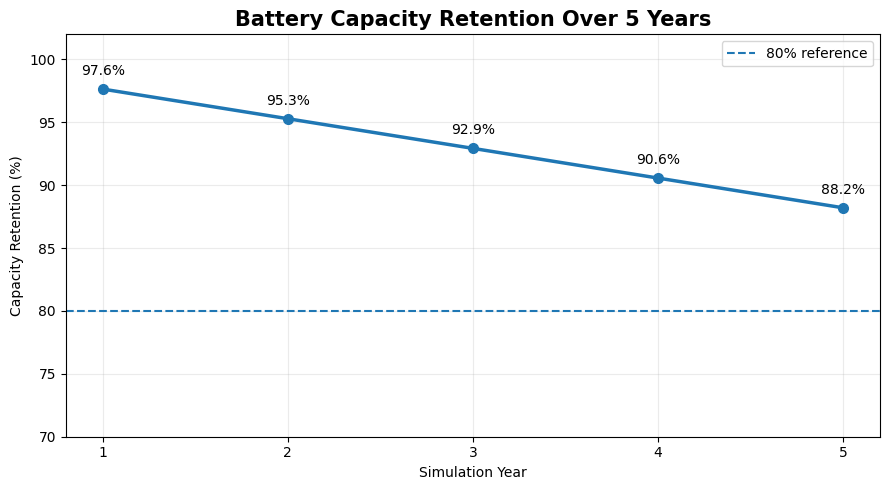

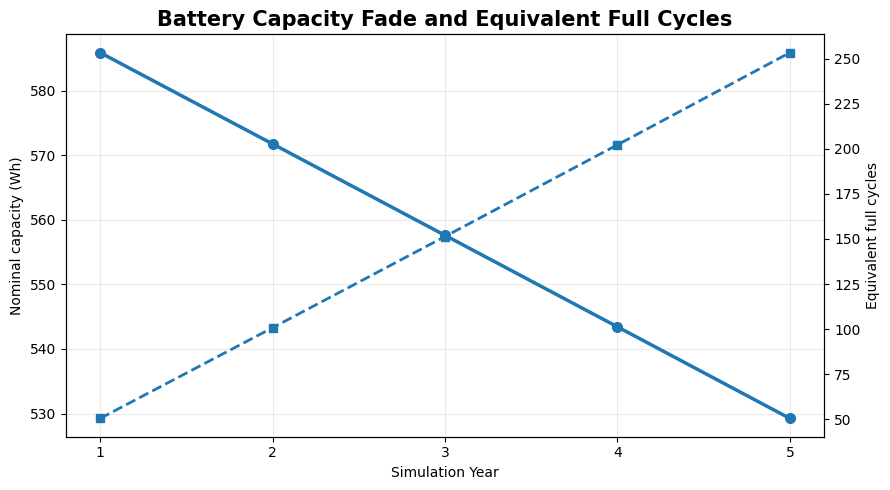

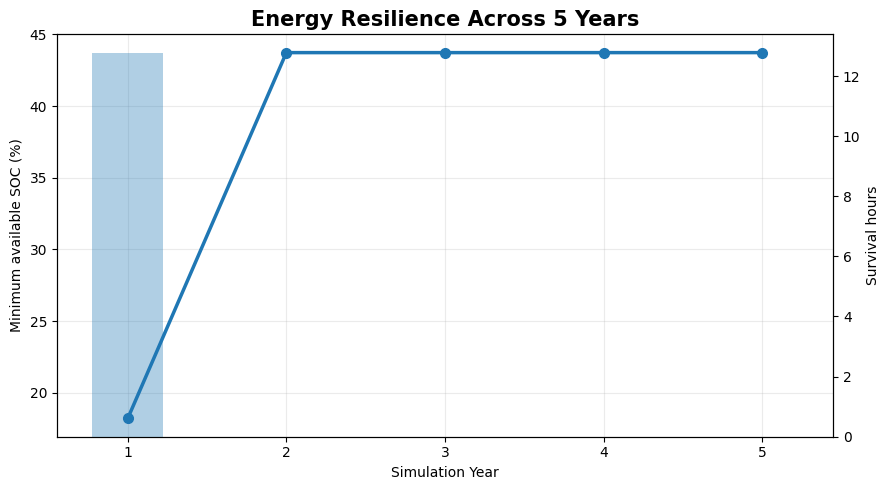

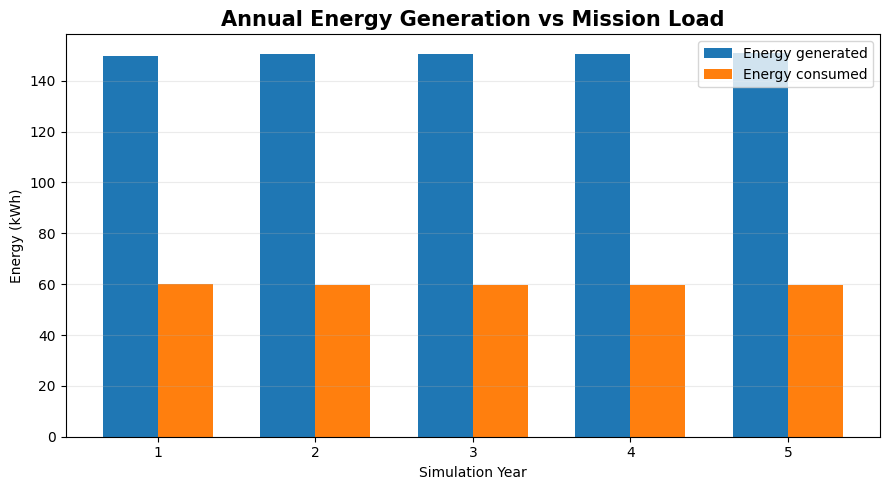


PPT KEY RESULTS
Initial battery capacity : 600.00 Wh
Final battery capacity   : 529.24 Wh
Capacity retention       : 88.21%
Capacity degradation     : 11.79%
Equivalent full cycles   : 253.30
Minimum available SOC    : 18.21%
Final available SOC      : 45.20%
Final charge efficiency  : 91.50%
Final discharge eff.     : 93.50%
Total survival hours     : 12.75 h
Total shutdown hours     : 0.00 h
Total unmet load         : 0.00 Wh

Files created:
  5_year_annual_analysis.csv
  PPT_capacity_retention.png
  PPT_capacity_vs_cycles.png
  PPT_energy_resilience.png
  PPT_energy_balance.png


In [32]:
# ============================================================
# PPT-READY: 5-YEAR DEGRADATION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Find the 5-year simulation dataframe automatically
# ------------------------------------------------------------
candidate_names = [
    "df_5year",
    "df_5y",
    "results_5year",
    "df_5yr",
    "five_year_df",
    "results_5y"
]

df5 = None

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        if isinstance(obj, pd.DataFrame) and len(obj) > 100000:
            df5 = obj.copy()
            print(f"Using dataframe: {name}")
            break

if df5 is None:
    raise ValueError(
        "5-year dataframe not found. Set df5 = <your 1825-day simulation dataframe> "
        "and run this cell again."
    )

# ------------------------------------------------------------
# Create year column if needed
# ------------------------------------------------------------
if "year" not in df5.columns:
    df5["year"] = np.floor(df5["day"] / 365).astype(int) + 1

# Correct final boundary
df5["year"] = df5["year"].clip(1, 5)

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------
def hours_in_mode(group, mode):
    if "mode" not in group.columns:
        return 0.0
    return (group["mode"] == mode).sum() * 0.25

# ------------------------------------------------------------
# Annual summary
# ------------------------------------------------------------
annual_rows = []

for yr, g in df5.groupby("year", sort=True):

    # Energy
    solar = g["solar_watts"].sum() * 0.25
    wave = g["wave_watts"].sum() * 0.25
    generation = solar + wave
    load = g["load_watts"].sum() * 0.25

    # Battery
    min_soc = g["soc_available"].min() * 100
    final_soc = g["soc_available"].iloc[-1] * 100
    final_nominal_soc = g["soc_nominal"].iloc[-1] * 100

    capacity = g["nominal_capacity_wh"].iloc[-1]
    capacity_retention = capacity / 600 * 100
    degradation = 100 - capacity_retention

    efc = g["equivalent_full_cycles"].iloc[-1]

    charge_eff = g["charge_efficiency"].iloc[-1] * 100
    discharge_eff = g["discharge_efficiency"].iloc[-1] * 100

    survival_h = hours_in_mode(g, "SURVIVAL")
    shutdown_h = hours_in_mode(g, "SHUTDOWN")

    unmet = g["unmet_load_wh"].sum()

    annual_rows.append({
        "Year": int(yr),
        "Solar (kWh)": solar / 1000,
        "Wave (kWh)": wave / 1000,
        "Total generation (kWh)": generation / 1000,
        "Load (kWh)": load / 1000,
        "Capacity (Wh)": capacity,
        "Capacity retention (%)": capacity_retention,
        "Degradation (%)": degradation,
        "EFC": efc,
        "Min available SOC (%)": min_soc,
        "Final available SOC (%)": final_soc,
        "Charge efficiency (%)": charge_eff,
        "Discharge efficiency (%)": discharge_eff,
        "Survival hours": survival_h,
        "Shutdown hours": shutdown_h,
        "Unmet load (Wh)": unmet
    })

annual = pd.DataFrame(annual_rows)

# ------------------------------------------------------------
# Display PPT table
# ------------------------------------------------------------
print("\n" + "="*110)
print("5-YEAR BATTERY DEGRADATION & MISSION PERFORMANCE")
print("="*110)

ppt_table = annual[
    [
        "Year",
        "Capacity (Wh)",
        "Capacity retention (%)",
        "Degradation (%)",
        "EFC",
        "Min available SOC (%)",
        "Charge efficiency (%)",
        "Discharge efficiency (%)",
        "Survival hours",
        "Unmet load (Wh)"
    ]
].copy()

print(ppt_table.round(2).to_string(index=False))

# ------------------------------------------------------------
# Save table
# ------------------------------------------------------------
annual.to_csv("5_year_annual_analysis.csv", index=False)

# ============================================================
# GRAPH 1 — BATTERY CAPACITY RETENTION
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    annual["Year"],
    annual["Capacity retention (%)"],
    marker="o",
    linewidth=2.5,
    markersize=7
)

plt.axhline(
    80,
    linestyle="--",
    linewidth=1.5,
    label="80% reference"
)

for x, y in zip(
    annual["Year"],
    annual["Capacity retention (%)"]
):
    plt.annotate(
        f"{y:.1f}%",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

plt.title(
    "Battery Capacity Retention Over 5 Years",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Simulation Year")
plt.ylabel("Capacity Retention (%)")
plt.xticks(range(1, 6))
plt.ylim(70, 102)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    "PPT_capacity_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 2 — CAPACITY + EFC
# ============================================================

fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(
    annual["Year"],
    annual["Capacity (Wh)"],
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Battery capacity"
)

ax1.set_xlabel("Simulation Year")
ax1.set_ylabel("Nominal capacity (Wh)")
ax1.set_xticks(range(1, 6))
ax1.grid(alpha=0.25)

ax2 = ax1.twinx()

ax2.plot(
    annual["Year"],
    annual["EFC"],
    marker="s",
    linewidth=2,
    markersize=6,
    linestyle="--",
    label="Equivalent full cycles"
)

ax2.set_ylabel("Equivalent full cycles")

plt.title(
    "Battery Capacity Fade and Equivalent Full Cycles",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout()

plt.savefig(
    "PPT_capacity_vs_cycles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 3 — SOC + SURVIVAL
# ============================================================

fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(
    annual["Year"],
    annual["Min available SOC (%)"],
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Minimum available SOC"
)

ax1.set_xlabel("Simulation Year")
ax1.set_ylabel("Minimum available SOC (%)")
ax1.set_xticks(range(1, 6))
ax1.grid(alpha=0.25)

ax2 = ax1.twinx()

ax2.bar(
    annual["Year"],
    annual["Survival hours"],
    alpha=0.35,
    width=0.45,
    label="Survival hours"
)

ax2.set_ylabel("Survival hours")

plt.title(
    "Energy Resilience Across 5 Years",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout()

plt.savefig(
    "PPT_energy_resilience.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 4 — ANNUAL ENERGY GENERATION VS LOAD
# ============================================================

plt.figure(figsize=(9, 5))

x = np.arange(len(annual))
width = 0.35

plt.bar(
    x - width/2,
    annual["Total generation (kWh)"],
    width,
    label="Energy generated"
)

plt.bar(
    x + width/2,
    annual["Load (kWh)"],
    width,
    label="Energy consumed"
)

plt.xticks(x, annual["Year"])
plt.xlabel("Simulation Year")
plt.ylabel("Energy (kWh)")

plt.title(
    "Annual Energy Generation vs Mission Load",
    fontsize=15,
    fontweight="bold"
)

plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    "PPT_energy_balance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FINAL KEY NUMBERS FOR PPT
# ============================================================

final = annual.iloc[-1]

print("\n" + "="*70)
print("PPT KEY RESULTS")
print("="*70)

print(f"Initial battery capacity : 600.00 Wh")
print(f"Final battery capacity   : {final['Capacity (Wh)']:.2f} Wh")
print(f"Capacity retention       : {final['Capacity retention (%)']:.2f}%")
print(f"Capacity degradation     : {final['Degradation (%)']:.2f}%")
print(f"Equivalent full cycles   : {final['EFC']:.2f}")
print(f"Minimum available SOC    : {annual['Min available SOC (%)'].min():.2f}%")
print(f"Final available SOC      : {final['Final available SOC (%)']:.2f}%")
print(f"Final charge efficiency  : {final['Charge efficiency (%)']:.2f}%")
print(f"Final discharge eff.     : {final['Discharge efficiency (%)']:.2f}%")
print(f"Total survival hours     : {annual['Survival hours'].sum():.2f} h")
print(f"Total shutdown hours     : {annual['Shutdown hours'].sum():.2f} h")
print(f"Total unmet load         : {annual['Unmet load (Wh)'].sum():.2f} Wh")

print("\nFiles created:")
print("  5_year_annual_analysis.csv")
print("  PPT_capacity_retention.png")
print("  PPT_capacity_vs_cycles.png")
print("  PPT_energy_resilience.png")
print("  PPT_energy_balance.png")

In [35]:
# ============================================================
# STEP 4 — BASELINE CHECK
# ============================================================

sim_baseline = BuoySimulation5Year(sim_cfg)

df_baseline = sim_baseline.run()

print("Baseline 5-Year Simulation")
print("=" * 40)

print(f"Rows                  : {len(df_baseline):,}")
print(f"Final Capacity        : {df_baseline['nominal_capacity_wh'].iloc[-1]:.2f} Wh")
print(f"Capacity Retention    : {(df_baseline['nominal_capacity_wh'].iloc[-1] / 600) * 100:.2f}%")
print(f"Capacity Degradation  : {df_baseline['degradation_fraction'].iloc[-1] * 100:.2f}%")
print(f"EFC                   : {df_baseline['equivalent_full_cycles'].iloc[-1]:.2f}")
print(f"Minimum Available SOC : {df_baseline['soc_available'].min() * 100:.2f}%")
print(f"Final Available SOC   : {df_baseline['soc_available'].iloc[-1] * 100:.2f}%")
print(f"Unmet Load            : {df_baseline['unmet_load_wh'].sum():.2f} Wh")
print(f"Shutdown Hours        : {(df_baseline['mode'] == 'SHUTDOWN').sum() * sim_cfg.dt_hours:.2f} h")

Baseline 5-Year Simulation
Rows                  : 175,200
Final Capacity        : 529.24 Wh
Capacity Retention    : 88.21%
Capacity Degradation  : 11.79%
EFC                   : 253.30
Minimum Available SOC : 18.21%
Final Available SOC   : 45.20%
Unmet Load            : 0.00 Wh
Shutdown Hours        : 0.00 h


In [36]:
# ============================================================
# STEP 5 — SENSITIVITY ANALYSIS
# ============================================================

def run_sensitivity(parameter, values):

    results = []

    for value in values:

        if parameter == "battery":
            sim = BuoySimulation5Year(
                sim_cfg,
                battery_capacity_wh=value
            )

        elif parameter == "solar":
            sim = BuoySimulation5Year(
                sim_cfg,
                solar_factor=value
            )

        elif parameter == "wave":
            sim = BuoySimulation5Year(
                sim_cfg,
                wave_factor=value
            )

        elif parameter == "degradation":
            sim = BuoySimulation5Year(
                sim_cfg,
                degradation_factor=value
            )

        df = sim.run()

        results.append({
            "Parameter": parameter,
            "Value": value,
            "Final Capacity (Wh)": df["nominal_capacity_wh"].iloc[-1],
            "Retention (%)": (
                df["nominal_capacity_wh"].iloc[-1]
                / sim.battery_capacity_wh
                * 100
            ),
            "Degradation (%)": (
                df["degradation_fraction"].iloc[-1] * 100
            ),
            "EFC": df["equivalent_full_cycles"].iloc[-1],
            "Min SOC (%)": df["soc_available"].min() * 100,
            "Final SOC (%)": df["soc_available"].iloc[-1] * 100,
            "Survival Hours": (
                (df["mode"] == "SURVIVAL").sum()
                * sim_cfg.dt_hours
            ),
            "Shutdown Hours": (
                (df["mode"] == "SHUTDOWN").sum()
                * sim_cfg.dt_hours
            ),
            "Unmet Load (Wh)": df["unmet_load_wh"].sum()
        })

    return pd.DataFrame(results)

In [37]:
battery_results = run_sensitivity(
    "battery",
    [400, 500, 600, 700, 800]
)

battery_results

,Parameter,Value,Final Capacity (Wh),Retention (%),Degradation (%),EFC,Min SOC (%),Final SOC (%),Survival Hours,Shutdown Hours,Unmet Load (Wh)
0,battery,400,347.786652,86.946663,13.053337,379.324865,17.432585,45.203009,35.00,0.0,0.0
1,battery,500,438.513773,87.702755,12.297245,303.715716,19.489465,45.203009,28.50,0.0,0.0
2,battery,600,529.241665,88.206944,11.793056,253.296763,18.212874,45.203009,12.75,0.0,0.0
3,battery,700,619.971141,88.567306,11.432694,217.260596,19.344712,45.203009,7.50,0.0,0.0
4,battery,800,710.702881,88.837860,11.162140,190.205161,22.991631,45.203009,0.00,0.0,0.0


In [38]:
solar_results = run_sensitivity(
    "solar",
    [0.8, 0.9, 1.0, 1.1, 1.2]
)

solar_results

,Parameter,Value,Final Capacity (Wh),Retention (%),Degradation (%),EFC,Min SOC (%),Final SOC (%),Survival Hours,Shutdown Hours,Unmet Load (Wh)
0,solar,0.8,529.120990,88.186832,11.813168,255.308009,19.339507,45.203009,30.50,0.0,0.0
1,solar,0.9,529.182689,88.197115,11.802885,254.279696,19.480325,45.203009,29.00,0.0,0.0
2,solar,1.0,529.241665,88.206944,11.793056,253.296763,18.212874,45.203009,12.75,0.0,0.0
3,solar,1.1,529.305538,88.217590,11.782410,252.232214,19.091634,45.203009,8.50,0.0,0.0
4,solar,1.2,529.371477,88.228579,11.771421,251.133227,19.339164,45.203009,5.75,0.0,0.0


In [39]:
wave_results = run_sensitivity(
    "wave",
    [0.5, 0.75, 1.0, 1.25, 1.5]
)

wave_results

,Parameter,Value,Final Capacity (Wh),Retention (%),Degradation (%),EFC,Min SOC (%),Final SOC (%),Survival Hours,Shutdown Hours,Unmet Load (Wh)
0,wave,0.50,528.363652,88.060609,11.939391,267.930317,19.297015,45.203009,29.25,0.0,0.0
1,wave,0.75,528.803434,88.133906,11.866094,260.600604,19.917153,45.203009,26.00,0.0,0.0
2,wave,1.00,529.241665,88.206944,11.793056,253.296763,18.212874,45.203009,12.75,0.0,0.0
3,wave,1.25,529.681160,88.280193,11.719807,245.971845,18.935855,45.203009,9.50,0.0,0.0
4,wave,1.50,530.120652,88.353442,11.646558,238.646979,19.656613,45.203009,6.00,0.0,0.0


In [40]:
degradation_results = run_sensitivity(
    "degradation",
    [0.5, 0.75, 1.0, 1.25, 1.5]
)

degradation_results

,Parameter,Value,Final Capacity (Wh),Retention (%),Degradation (%),EFC,Min SOC (%),Final SOC (%),Survival Hours,Shutdown Hours,Unmet Load (Wh)
0,degradation,0.50,564.619443,94.103241,5.896759,253.343066,18.209396,45.203009,12.75,0.0,0.0
1,degradation,0.75,546.930207,91.155034,8.844966,253.319914,18.211135,45.203009,12.75,0.0,0.0
2,degradation,1.00,529.241665,88.206944,11.793056,253.296763,18.212874,45.203009,12.75,0.0,0.0
3,degradation,1.25,511.553817,85.258970,14.741030,253.273612,18.214614,45.203009,12.75,0.0,0.0
4,degradation,1.50,493.866664,82.311111,17.688889,253.250463,18.216355,45.203009,12.75,0.0,0.0


In [42]:
# ============================================================
# MISSION RELIABILITY SUMMARY
# ============================================================

all_sensitivity = pd.concat([
    battery_sensitivity.assign(
        scenario="Battery capacity"
    ),
    solar_sensitivity.assign(
        scenario="Solar"
    ),
    wave_sensitivity.assign(
        scenario="WEC"
    ),
    degradation_sensitivity.assign(
        scenario="Degradation"
    )
], ignore_index=True)

print("\n" + "="*100)
print("MISSION RELIABILITY SUMMARY")
print("="*100)

print(
    all_sensitivity[
        [
            "scenario",
            "min_soc_pct",
            "survival_hours",
            "shutdown_hours",
            "unmet_load_wh"
        ]
    ].round(2).to_string(index=False)
)

NameError: name 'battery_sensitivity' is not defined